# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

In [2]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [3]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [4]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

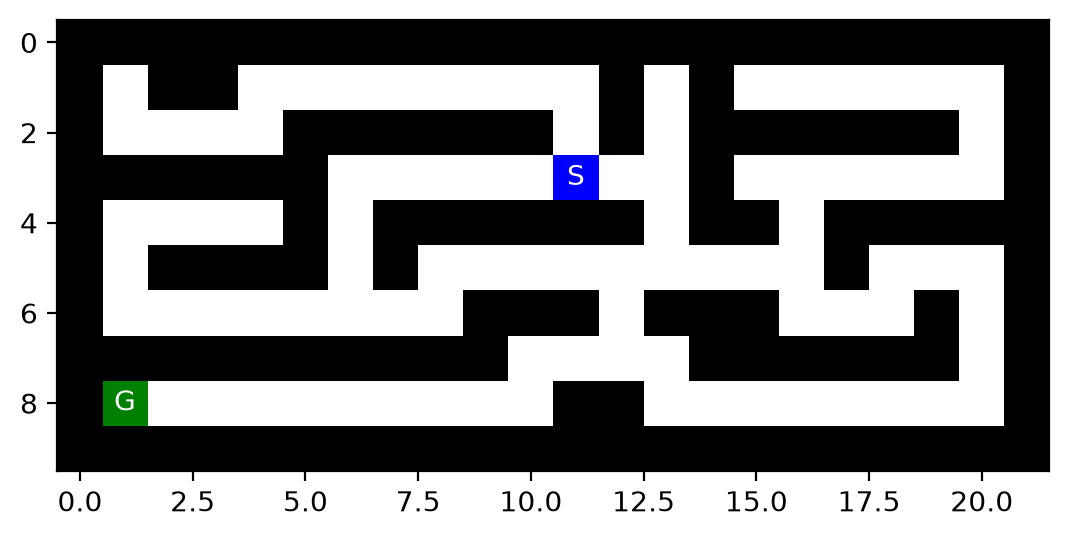

In [5]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [6]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [7]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [8]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [9]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['N', 'S', 'E', 'W', 'S', 'W', 'N', 'N', 'W', 'N']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [10]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: S
Following plan... step 1: W
Following plan... step 2: S
Following plan... step 3: W
Following plan... step 4: S
Following plan... step 5: W
Following plan... step 6: E
Following plan... step 7: W
Following plan... step 8: S
Following plan... step 9: N
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [11]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

**Thành phần của bài toán tìm kiếm**

| Thành phần | Mô tả trong bài toán mê cung |
|---|---|
| **Trạng thái** | Vị trí của tác tử $s = (r, c)$ (hàng, cột) trên một ô không phải tường. |
| **Trạng thái đầu** | $s_0 = $ vị trí của ô `S` (`find_pos(maze, "S")`). |
| **Hành động** | $A = \{N, E, S, W\}$. $\text{ACTIONS}(s)$ chỉ gồm các hướng mà ô kế tiếp **không phải tường** `X`. |
| **Mô hình chuyển trạng thái** | $\text{RESULT}((r,c), N) = (r-1, c)$, $\text{RESULT}((r,c), S) = (r+1, c)$, $\text{RESULT}((r,c), E) = (r, c+1)$, $\text{RESULT}((r,c), W) = (r, c-1)$. Môi trường tất định nên mỗi cặp (trạng thái, hành động) cho đúng một trạng thái mới. |
| **Trạng thái đích** | $\text{IS-GOAL}(s) \iff \text{maze}[s] = $ `G`. Cách kiểm tra theo ký tự cho phép có **nhiều đích** (phần nâng cao). |
| **Chi phí đường đi** | Mỗi bước có chi phí 1: $c(s, a, s') = 1$, nên chi phí đường đi $g(n)$ = số bước = độ sâu của nút. |

Các thành phần trên được cài đặt trực tiếp thành các hàm dưới đây. Lưu ý: các hàm chỉ **đọc** bản đồ, không ghi thông tin tìm kiếm vào bản đồ.

In [12]:
import time
import heapq
from collections import deque

import numpy as np

# Thứ tự hành động cố định để kết quả tái lập được.
DIRECTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}


def find_all(maze, what):
    """Tất cả vị trí (row, col) chứa ký tự `what` (dùng cho bài toán nhiều đích)."""
    return [tuple(int(v) for v in p) for p in zip(*np.where(maze == what))]


def actions(maze, pos):
    """ACTIONS(s): các hướng đi không dẫn vào tường."""
    r, c = pos
    return [a for a, (dr, dc) in DIRECTIONS.items() if maze[r + dr, c + dc] != "X"]


def result(pos, action):
    """RESULT(s, a): mô hình chuyển trạng thái."""
    dr, dc = DIRECTIONS[action]
    return (pos[0] + dr, pos[1] + dc)


def is_goal(maze, pos):
    """IS-GOAL(s)."""
    return maze[pos] == "G"


def expand(maze, node):
    """EXPAND(problem, node): sinh các nút con, mỗi bước có chi phí 1."""
    for a in actions(maze, node.pos):
        yield Node(result(node.pos, a), node, a, node.cost + 1)


print("Start:", find_all(maze, "S"), "- Goal:", find_all(maze, "G"))
print("ACTIONS(start) =", actions(maze, find_all(maze, "S")[0]))

Start: [(3, 11)] - Goal: [(8, 1)]
ACTIONS(start) = ['N', 'E', 'W']


Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

**Ước lượng kích thước bài toán**

* $n$ (kích thước không gian trạng thái): số ô **không phải tường** trong mê cung – đếm trực tiếp từ bản đồ.
* $d$ (độ sâu lời giải tối ưu): số bước của đường đi ngắn nhất từ `S` tới `G`. Không biết trước; xác định chính xác bằng BFS (chi phí bước bằng nhau nên BFS tối ưu) – xem bảng sau khi cài đặt BFS ở Task 2.
* $m$ (độ sâu tối đa của cây): nếu **không** kiểm tra chu trình thì $m = \infty$ (tác tử có thể đi qua lại mãi). Khi kiểm tra chu trình trên đường đi, mỗi đường đi là đường đơn nên $m \le n - 1$; đây là cận trên dùng để ước lượng.
* $b$ (hệ số phân nhánh tối đa): tối đa 4 hướng; tính chính xác bằng $\max_s |\text{ACTIONS}(s)|$ trên mọi ô trống. Hệ số phân nhánh hiệu dụng trong hành lang hẹp chỉ khoảng 1–2 (không tính đường quay lui), còn trong vùng trống là 3–4.

In [13]:
import pandas as pd

MAZE_FILES = {
    "small": "small_maze.txt", "medium": "medium_maze.txt", "large": "large_maze.txt",
    "open": "open_maze.txt", "L": "L_maze.txt", "loops": "loops_maze.txt",
    "empty": "empty_maze.txt", "empty_2": "empty_maze_2.txt",
}


def load_maze(file):
    with open(file, "r") as f:
        return mh.parse_maze(f.read())


MAZES = {name: load_maze(file) for name, file in MAZE_FILES.items()}


def problem_size(maze):
    free = [p for p in zip(*np.where(maze != "X"))]
    return {"n": len(free),
            "b": max(len(actions(maze, p)) for p in free),
            "m (cận trên)": len(free) - 1}


pd.DataFrame({name: problem_size(m) for name, m in MAZES.items()}).T

,n,b,m (cận trên)
small,94,3,93
medium,274,3,273
large,647,4,646
open,684,4,683
L,157,4,156
loops,72,4,71
empty,100,4,99
empty_2,100,4,99


## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [14]:
def make_result(goal_node, expanded, max_depth, max_frontier, max_memory,
                explored, frontier_states, start_time, **extra):
    """Đóng gói kết quả và các thống kê của một lần tìm kiếm."""
    res = {
        "path": None, "actions": None, "path_cost": None,
        "expanded": expanded,            # số nút được mở rộng
        "max_depth": max_depth,          # độ sâu lớn nhất của cây tìm kiếm
        "max_frontier": max_frontier,    # kích thước frontier lớn nhất
        "max_memory": max_memory,        # số nút tối đa cùng lúc trong bộ nhớ
        "explored": explored,            # chỉ để vẽ hình
        "frontier": frontier_states,     # chỉ để vẽ hình
        "time_ms": (time.perf_counter() - start_time) * 1000,
    }
    if goal_node is not None:
        nodes = goal_node.get_path_from_root()
        res["path"] = [n.pos for n in nodes]
        res["actions"] = [n.action for n in nodes[1:]]
        res["path_cost"] = goal_node.cost
    res.update(extra)
    return res


def bfs(maze):
    """Breadth-first search theo mã giả AIMA (Fig. 3.9).

    frontier: FIFO queue; reached: tập trạng thái đã sinh ra; kiểm tra đích sớm
    (early goal test) khi sinh nút con.
    """
    t0 = time.perf_counter()
    start = find_all(maze, "S")[0]
    node = Node(start, None, None, 0)
    if is_goal(maze, start):
        return make_result(node, 0, 0, 1, 1, set(), [], t0)

    frontier = deque([node])
    reached = {start}
    expanded = max_depth = 0
    max_frontier = 1
    explored = set()

    while frontier:
        node = frontier.popleft()
        expanded += 1
        explored.add(node.pos)
        for child in expand(maze, node):
            s = child.pos
            if is_goal(maze, s):
                max_depth = max(max_depth, child.cost)
                return make_result(child, expanded, max_depth, max_frontier, len(reached) + 1,
                                   explored, [n.pos for n in frontier], t0)
            if s not in reached:
                reached.add(s)
                frontier.append(child)
                max_depth = max(max_depth, child.cost)
        max_frontier = max(max_frontier, len(frontier))

    return make_result(None, expanded, max_depth, max_frontier, len(reached), explored, [], t0)


def on_path(node, pos):
    """Kiểm tra chu trình: pos có nằm trên đường đi từ gốc tới node không? O(độ sâu)."""
    while node is not None:
        if node.pos == pos:
            return True
        node = node.parent
    return False


def dfs(maze, limit=None, max_tries=100_000, frontier_option="move_top"):
    """Depth-first search KHÔNG dùng reached, có kiểm tra chu trình và giải phóng bộ nhớ.

    frontier_option (chiến lược kiểm tra chu trình, xem 05_..._Cycle_checking.ipynb):
      "path"     : chỉ bỏ các con đã xuất hiện trên đường đi hiện tại.
      "no_dup"   : như "path" + không thêm trạng thái đang có trong frontier.
      "move_top" : như "path" + nếu trạng thái đã có trong frontier thì đưa nó lên đỉnh stack.
    limit: giới hạn độ sâu (Depth-Limited Search). None = không giới hạn.
    max_tries: số lần lấy nút tối đa để tránh vòng lặp quá dài.
    """
    t0 = time.perf_counter()
    start = find_all(maze, "S")[0]
    root = Node(start, None, None, 0)
    root.n_children = 0              # số con còn sống -> dùng để giải phóng nhánh đã xong

    stack = [root]                   # frontier LIFO
    in_frontier = {start: root}      # trạng thái -> bản ghi hợp lệ trong frontier
    alive = 1                        # số nút đang được giữ trong bộ nhớ
    expanded = max_depth = 0
    max_frontier = max_memory = 1
    tries = 0
    cutoff = False
    explored = set()                 # CHỈ để vẽ hình, thuật toán không đọc tập này

    def release(node):
        """Giải phóng node và các tổ tiên không còn con nào trong cây."""
        nonlocal alive
        while node is not None and node.n_children == 0:
            alive -= 1
            node = node.parent
            if node is not None:
                node.n_children -= 1

    def live_frontier():
        return [n.pos for n in stack if not getattr(n, "removed", False)]

    while stack:
        tries += 1
        if tries > max_tries:
            return make_result(None, expanded, max_depth, max_frontier, max_memory, explored,
                               live_frontier(), t0, status="max_tries", tries=tries - 1)
        node = stack.pop()
        if getattr(node, "removed", False):
            release(node)            # bản ghi cũ đã được đưa lên đỉnh ở chỗ khác
            continue
        if in_frontier.get(node.pos) is node:
            del in_frontier[node.pos]

        if is_goal(maze, node.pos):
            return make_result(node, expanded, max_depth, max_frontier, max_memory, explored,
                               live_frontier(), t0, status="solved", tries=tries)
        if limit is not None and node.cost >= limit:
            cutoff = True
            release(node)
            continue

        expanded += 1
        explored.add(node.pos)
        for child in expand(maze, node):
            s = child.pos
            if on_path(node, s):
                continue                               # chu trình -> bỏ
            if s in in_frontier:
                if frontier_option == "no_dup":
                    continue
                if frontier_option == "move_top":
                    in_frontier[s].removed = True      # xóa lười bản ghi cũ
            child.n_children = 0
            node.n_children += 1
            alive += 1
            stack.append(child)
            in_frontier[s] = child
            max_depth = max(max_depth, child.cost)

        if node.n_children == 0:
            release(node)                              # lá cụt -> giải phóng ngay
        max_frontier = max(max_frontier, len(in_frontier) if frontier_option != "path" else len(stack))
        max_memory = max(max_memory, alive)

    return make_result(None, expanded, max_depth, max_frontier, max_memory, explored, [], t0,
                       status="cutoff" if cutoff else "failure", tries=tries)

**Hiển thị lời giải.** Hàm `show_solutions()` dùng cùng bảng màu với `mh.show_maze()`: đen = tường, xám = ô đã mở rộng, cam = ô còn trong frontier, đỏ = đường đi tìm được, xanh dương/xanh lá = `S`/`G`. Bản đồ chỉ được sao chép để vẽ, thuật toán không ghi gì vào bản đồ.

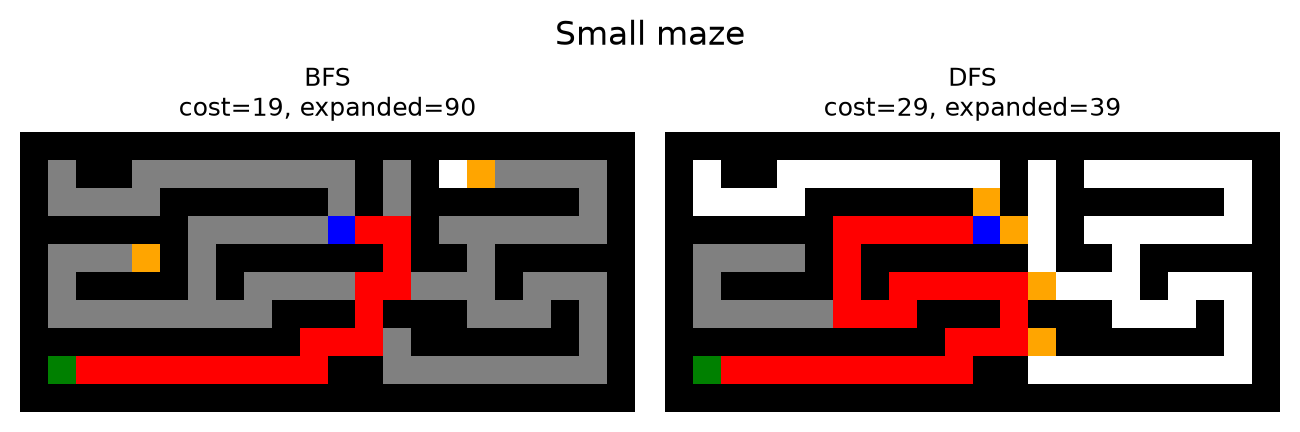

In [15]:
import matplotlib.pyplot as plt
from matplotlib import colors

CMAP = colors.ListedColormap(["white", "black", "blue", "green", "red", "gray", "orange"])
NORM = colors.BoundaryNorm(list(range(8)), 7)
CODES = {" ": 0, "X": 1, "S": 2, "G": 3, "P": 4, ".": 5, "F": 6}


def solution_maze(maze, res):
    """Bản sao của mê cung, đánh dấu ô đã mở rộng, frontier và đường đi."""
    m = np.copy(maze)
    for p in res["explored"]:
        if m[p] == " ":
            m[p] = "."
    for p in res["frontier"]:
        if m[p] in " .":
            m[p] = "F"
    for p in res["path"] or []:
        if m[p] not in "SG":
            m[p] = "P"
    return m


def show_solutions(maze, results, title=None):
    """Vẽ lời giải của nhiều thuật toán cạnh nhau."""
    k = len(results)
    rows, cols = maze.shape
    fig, axes = plt.subplots(1, k, figsize=(3.3 * k, 3.3 * rows / cols + 0.8))
    axes = np.atleast_1d(axes)
    for ax, (name, res) in zip(axes, results.items()):
        m = np.vectorize(CODES.get)(solution_maze(maze, res))
        ax.imshow(m, cmap=CMAP, norm=NORM)
        cost = res["path_cost"] if res["path"] else "N/A"
        ax.set_title(f"{name}\ncost={cost}, expanded={res['expanded']}", fontsize=9)
        ax.axis("off")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


small = MAZES["small"]
show_solutions(small, {"BFS": bfs(small), "DFS": dfs(small)}, "Small maze")

Sau khi có BFS, xác định chính xác độ sâu lời giải tối ưu $d$ cho từng mê cung (cột $d$), cùng với $n$, $m$ (cận trên) và $b$:

In [16]:
sizes = pd.DataFrame({name: problem_size(m) for name, m in MAZES.items()}).T
sizes.insert(1, "d", [bfs(m)["path_cost"] for m in MAZES.values()])
sizes

,n,d,b,m (cận trên)
small,94,19,3,93
medium,274,68,3,273
large,647,210,4,646
open,684,54,4,683
L,157,16,4,156
loops,72,23,4,71
empty,100,14,4,99
empty_2,100,14,4,99


How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

**BFS** dùng cấu trúc `reached` (tập trạng thái đã sinh). Một trạng thái chỉ được đưa vào frontier lần đầu tiên nó được sinh ra; các đường khác dẫn tới trạng thái đó (kể cả chu trình quay lại) đều bị loại. Vì vậy BFS không bao giờ lặp lại trạng thái – nó loại bỏ cả **chu trình** lẫn **đường đi dư thừa (redundant paths)**, đổi lại phải lưu toàn bộ `reached`.

**DFS (không có reached)** chỉ còn thông tin là cây đang nằm trong bộ nhớ, nên chỉ có thể **kiểm tra chu trình**: khi mở rộng nút $n$, không sinh con có trạng thái đã nằm trên đường đi từ gốc tới $n$ (`on_path`, chi phí $O(\text{độ sâu})$). Điều này chặn được vòng lặp vô hạn (mỗi nhánh là một đường đơn, nên độ sâu $\le n-1$) nhưng **không** chặn được đường đi dư thừa: một ô có thể được thăm lại từ nhánh khác. Trong vùng trống (open, empty, L maze), số đường đơn tăng theo hàm mũ, nên DFS chỉ kiểm tra đường đi sẽ quét đi quét lại cùng một vùng (xem 05_Maze_Example-Animation_Cycle_checking.ipynb).

Để khắc phục, cài đặt `dfs()` dùng thêm bảng `in_frontier` (chỉ chứa các trạng thái **đang** trong frontier, nên vẫn có kích thước $O(bm)$): nếu con đã có trong frontier thì bản ghi cũ bị đánh dấu xóa và bản ghi mới được đặt lên đỉnh stack (`frontier_option="move_top"`). Khi một nhánh không còn nút con nào trong frontier, các nút của nhánh đó được giải phóng (`release`) – đây là lý do DFS chỉ cần bộ nhớ $O(bm)$.

Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

Ký hiệu: $n$ số trạng thái, $b$ hệ số phân nhánh, $d$ độ sâu lời giải nông nhất, $m$ độ sâu tối đa.

| | BFS (có `reached`) | DFS (không `reached`, kiểm tra chu trình) |
|---|---|---|
| **Đầy đủ** | Có – không gian trạng thái hữu hạn, mỗi trạng thái vào frontier tối đa một lần. | Có trong không gian hữu hạn: kiểm tra chu trình biến mọi nhánh thành đường đơn nên cây hữu hạn. Thực tế có thể "kẹt" rất lâu trong vùng trống nên cài đặt dùng `max_tries`; với `move_top`, mọi mê cung trong bài đều giải được. |
| **Tối ưu** | Có – mọi bước có chi phí 1, BFS tìm lời giải nông nhất. | Không – trả về lời giải đầu tiên gặp theo thứ tự đi sâu (ví dụ L maze: 122 bước so với tối ưu 16). |
| **Thời gian** | $O(b^d)$, nhưng với `reached` mỗi ô mở rộng tối đa một lần nên bị chặn bởi $O(n)$. | $O(b^m)$ trong trường hợp xấu nhất (số đường đơn), $m \le n-1$. Mỗi lần kiểm tra chu trình tốn thêm $O(m)$. |
| **Bộ nhớ** | $O(b^d)$, bị chặn bởi $O(n)$: phải lưu cả `reached` và frontier. | $O(bm)$: chỉ lưu đường đi hiện tại và các nút anh em chưa thăm; nhánh đã xong được giải phóng. |

**Khác biệt về bộ nhớ.** BFS phải nhớ mọi trạng thái đã gặp (`reached`), nên bộ nhớ tỉ lệ với vùng đã khảo sát; DFS chỉ giữ một đường đi cùng các anh em của nó. Trong bảng ở Task 4, cột `max # of nodes in memory` cho thấy điều này rõ ở mê cung lớn: large maze BFS giữ 622 nút, DFS chỉ 251 dù đi đường gần như cùng chiều dài. Ngược lại trong mê cung trống, đường đi DFS rất dài nên bộ nhớ $O(bm)$ cũng lớn (empty maze: 153 nút so với 96 của BFS) – $m$ lớn làm mất lợi thế.

## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

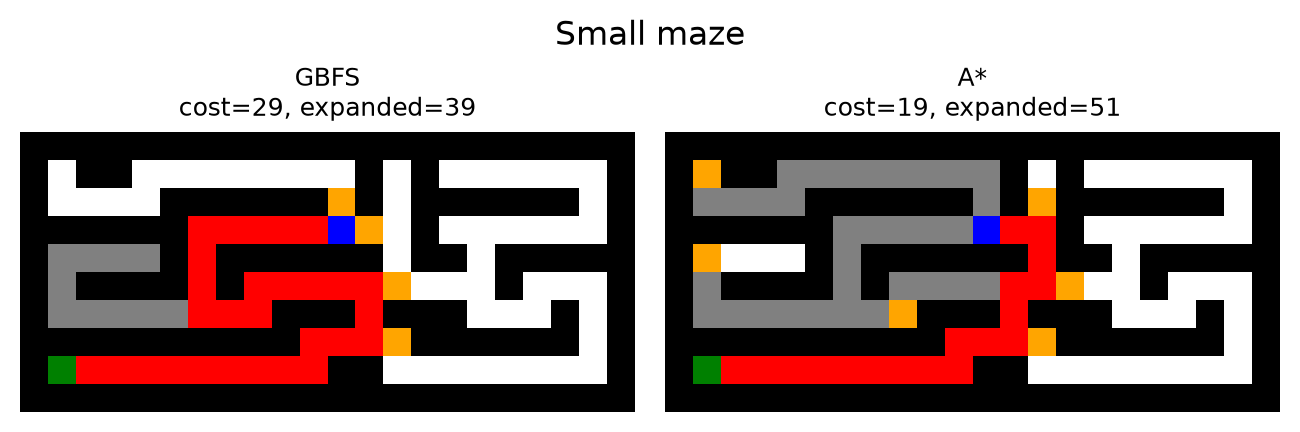

In [17]:
def manhattan(pos, goals):
    """Khoảng cách Manhattan tới đích gần nhất."""
    return min(abs(pos[0] - g[0]) + abs(pos[1] - g[1]) for g in goals)


def euclidean(pos, goals):
    return min(((pos[0] - g[0]) ** 2 + (pos[1] - g[1]) ** 2) ** 0.5 for g in goals)


def best_first_search(maze, strategy="A*", heuristic=manhattan, w=1.0):
    """Best-first search (AIMA Fig. 3.7) với hàm đánh giá:

      GBFS:        f(n) = h(n)
      A*:          f(n) = g(n) + h(n)
      Weighted A*: f(n) = g(n) + w * h(n)

    frontier: priority queue (heapq); reached: dict trạng thái -> nút tốt nhất.
    Kiểm tra đích khi lấy nút ra khỏi frontier (cần cho tính tối ưu của A*).
    Hòa điểm f: ưu tiên nút được thêm sau cùng (LIFO) để giữ hướng đi.
    """
    t0 = time.perf_counter()
    start = find_all(maze, "S")[0]
    goals = find_all(maze, "G")

    def f(node):
        h = heuristic(node.pos, goals)
        return h if strategy == "GBFS" else node.cost + w * h

    counter = 0
    node = Node(start, None, None, 0)
    frontier = [(f(node), -counter, node)]
    reached = {start: node}
    expanded = max_depth = 0
    max_frontier = 1
    explored = set()

    while frontier:
        _, _, node = heapq.heappop(frontier)
        if node is not reached[node.pos]:
            continue                       # bản ghi lỗi thời: đã có đường tốt hơn
        if is_goal(maze, node.pos):
            return make_result(node, expanded, max_depth, max_frontier, len(reached),
                               explored, [n.pos for _, _, n in frontier], t0)
        expanded += 1
        explored.add(node.pos)
        for child in expand(maze, node):
            s = child.pos
            # GBFS không quan tâm g(n) nên không mở lại trạng thái đã gặp;
            # A* cập nhật nếu tìm được đường rẻ hơn.
            better = strategy != "GBFS" and s in reached and child.cost < reached[s].cost
            if s not in reached or better:
                reached[s] = child
                counter += 1
                heapq.heappush(frontier, (f(child), -counter, child))
                max_depth = max(max_depth, child.cost)
        max_frontier = max(max_frontier, len(frontier))

    return make_result(None, expanded, max_depth, max_frontier, len(reached), explored, [], t0)


def gbfs(maze):
    return best_first_search(maze, "GBFS")


def astar(maze):
    return best_first_search(maze, "A*")


show_solutions(small, {"GBFS": gbfs(small), "A*": astar(small)}, "Small maze")

Are your implementations complete and optimal? What is the time and space complexity?

**Greedy best-first search** ($f(n) = h(n)$, có `reached`)

* *Đầy đủ*: Có, vì không gian trạng thái hữu hạn và `reached` ngăn mở rộng lại một trạng thái (bản dạng tree-search không có `reached` có thể lặp vô hạn).
* *Tối ưu*: Không. GBFS bỏ qua $g(n)$, chỉ chạy về phía ô có vẻ gần đích nhất. Ví dụ small maze: GBFS đi 29 bước, tối ưu là 19; medium maze: 152 so với 68.
* *Thời gian/Bộ nhớ*: Trường hợp xấu $O(b^m)$, với `reached` bị chặn bởi $O(n \log n)$ (thao tác heap). Với heuristic tốt có thể rất nhanh (empty maze: chỉ mở rộng 14 nút).

**A\*** ($f(n) = g(n) + h(n)$, $h$ = Manhattan)

* *Đầy đủ*: Có (chi phí bước dương, không gian hữu hạn).
* *Tối ưu*: Có. Manhattan là heuristic **chấp nhận được** ($h(n) \le h^*(n)$ vì chỉ đi 4 hướng và mỗi bước giảm khoảng cách tối đa 1) và **nhất quán** ($h(n) \le 1 + h(n')$). Với heuristic nhất quán, lần đầu một trạng thái được lấy ra khỏi frontier là đã có đường tối ưu tới nó, nên kiểm tra đích khi lấy nút ra bảo đảm tối ưu.
* *Thời gian/Bộ nhớ*: Trường hợp xấu $O(b^d)$ (khi $h$ kém, A\* thoái hóa thành uniform-cost search); với `reached` bị chặn bởi $O(n \log n)$ thời gian và $O(n)$ bộ nhớ. A\* mở rộng mọi nút có $f(n) < C^*$, nên heuristic càng sát $h^*$ thì càng ít nút.

## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [18]:
ALGORITHMS = {
    "BFS": bfs,
    "DFS": dfs,
    "GBFS": gbfs,
    "A*": astar,
}

results = {m: {a: alg(MAZES[m]) for a, alg in ALGORITHMS.items()} for m in MAZES}


def to_row(maze_name, alg, res):
    return {
        "maze": maze_name, "algorithm": alg,
        "path cost": res["path_cost"] if res["path"] else "N/A*",
        "# of nodes expanded": res["expanded"],
        "max tree depth": res["max_depth"],
        "max # of nodes in memory": res["max_memory"],
        "max frontier size": res["max_frontier"],
        "time (ms)": round(res["time_ms"], 2),
    }


table = pd.DataFrame([to_row(m, a, r) for m, rs in results.items() for a, r in rs.items()])
table.set_index(["maze", "algorithm"])

path cost  # of nodes expanded  max tree depth  \
maze    algorithm                                                   
small   BFS               19                   90              19   
        DFS               29                   39              29   
        GBFS              29                   39              29   
        A*                19                   51              19   
medium  BFS               68                  267              68   
        DFS              152                  153             152   
        GBFS             152                  155             152   
        A*                68                  217              68   
large   BFS              210                  618             210   
        DFS              210                  337             214   
        GBFS             210                  456             210   
        A*               210                  542             210   
open    BFS               54                  679              54   
        DFS               54                  211             178   
        GBFS              54                  211              67   
        A*                54                  211              54   
L       BFS               16                  146              16   
        DFS              122                  132             122   
        GBFS              16                   33              16   
        A*                16                   40              16   
loops   BFS               23                   70              23   
        DFS               27                   30              27   
        GBFS              41                   51              41   
        A*                23                   51              23   
empty   BFS               14                   92              14   
        DFS               80                   80              80   
        GBFS              14                   14              14   
        A*                14                   14              14   
empty_2 BFS               14                   92              14   
        DFS               34                   34              34   
        GBFS              14                   14              14   
        A*                14                   14              14   

                   max # of nodes in memory  max frontier size  time (ms)  
maze    algorithm                                                          
small   BFS                              93                  9       0.26  
        DFS                              34                  5       0.14  
        GBFS                             44                  5       0.14  
        A*                               58                  7       0.18  
medium  BFS                             270                  9       0.68  
        DFS                             160                  8       0.82  
        GBFS                            163                  8       0.53  
        A*                              224                  8       0.67  
large   BFS                             622                  8       1.47  
        DFS                             251                 38       2.08  
        GBFS                            481                 25       1.51  
        A*                              553                 12       1.65  
open    BFS                             683                 25       2.07  
        DFS                             333                 64       1.78  
        GBFS                            275                 64       0.84  
        A*                              275                185       0.96  
L       BFS                             152                 17       0.50  
        DFS                             231                 23       0.91  
        GBFS                             64                 31       0.15  
        A*                               69                 29       0.19  


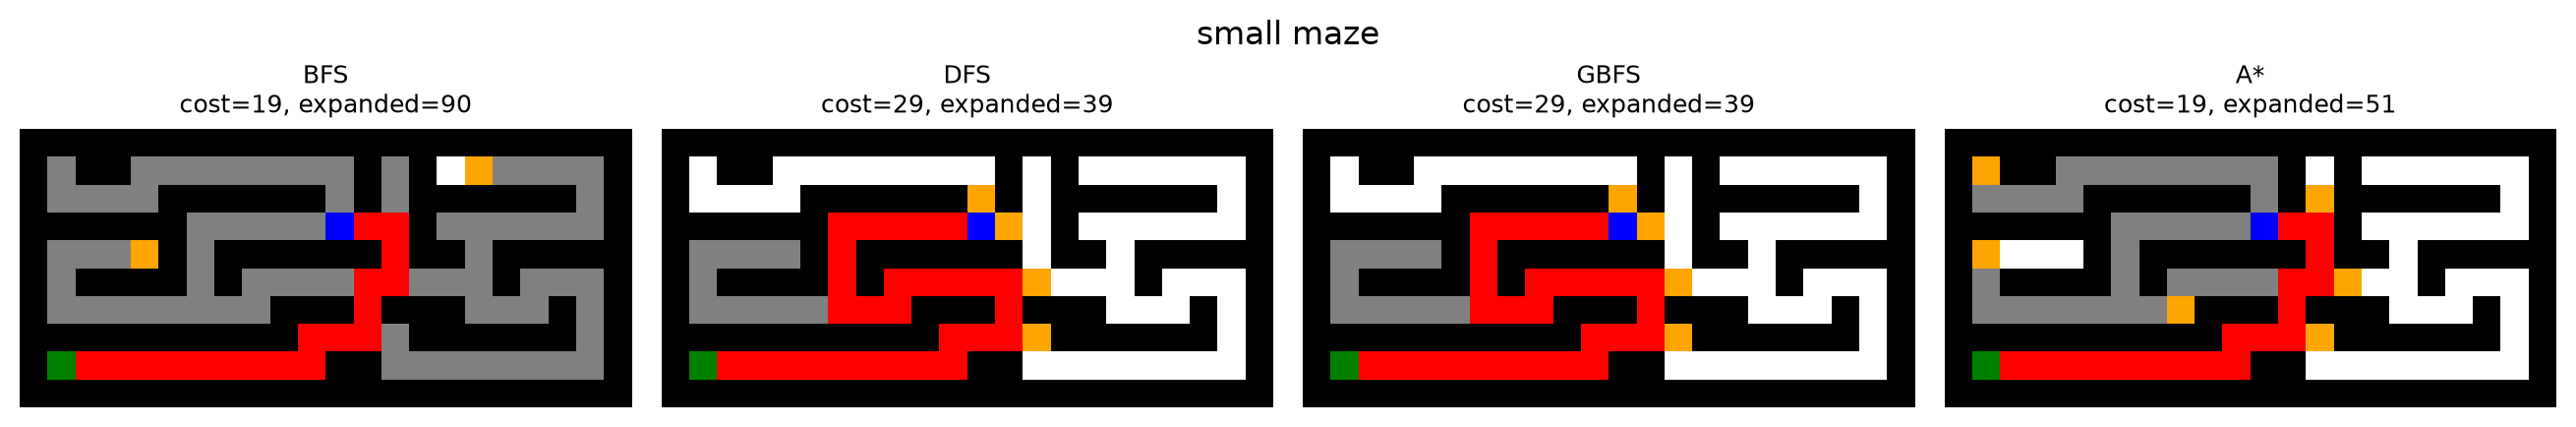

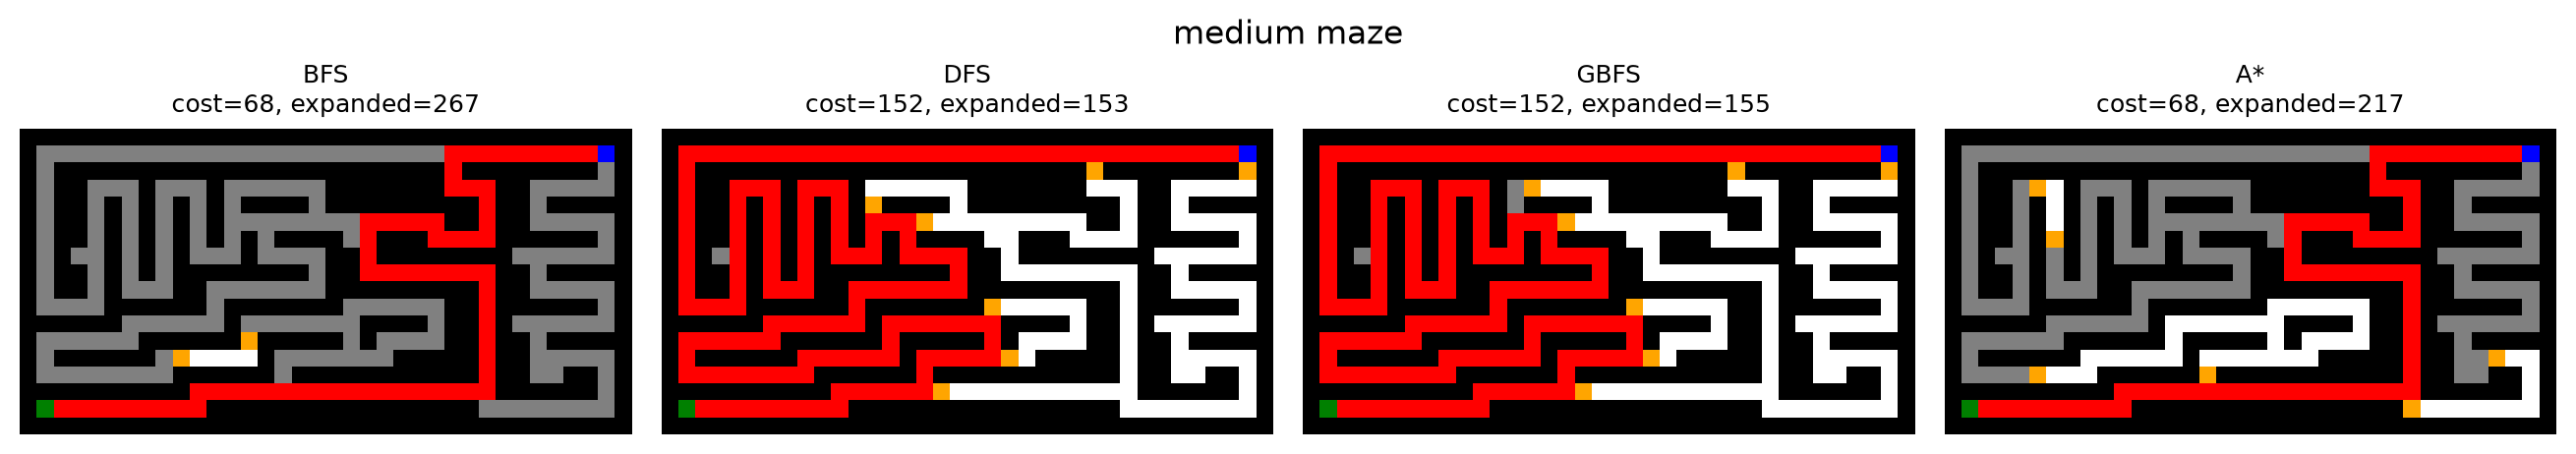

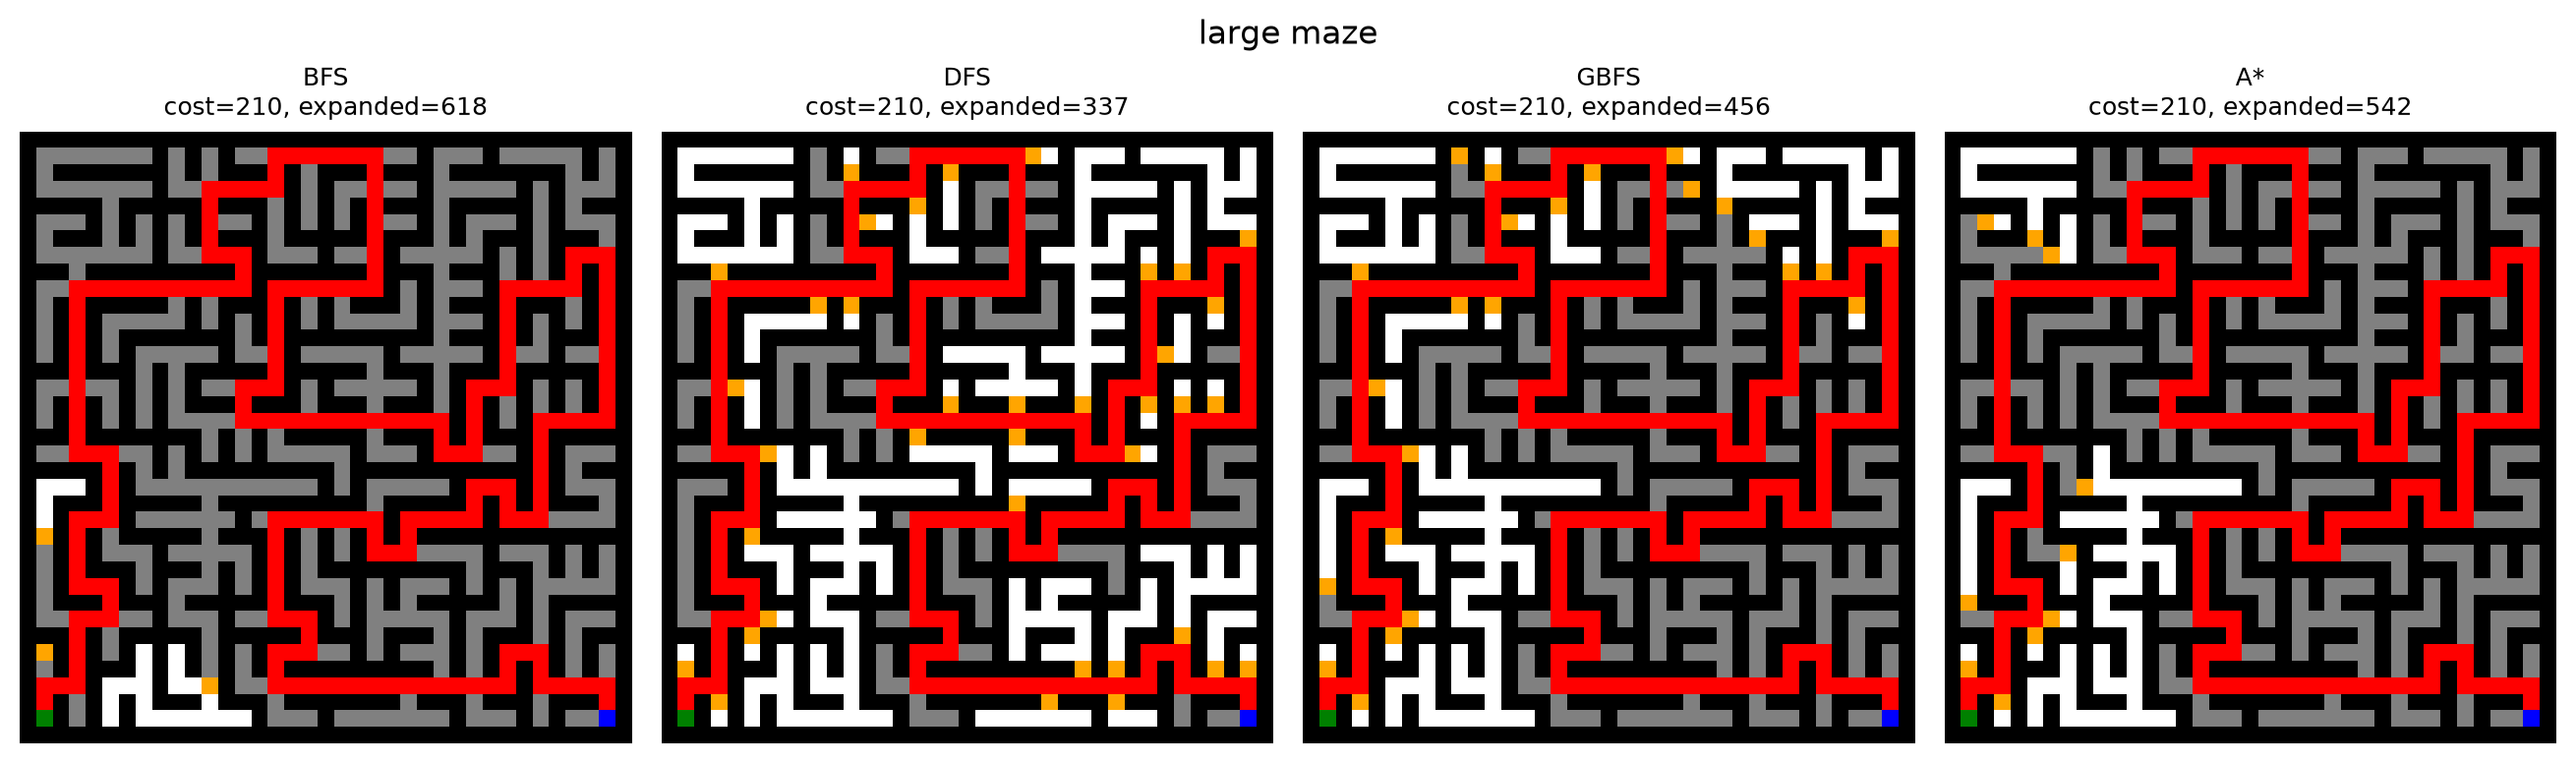

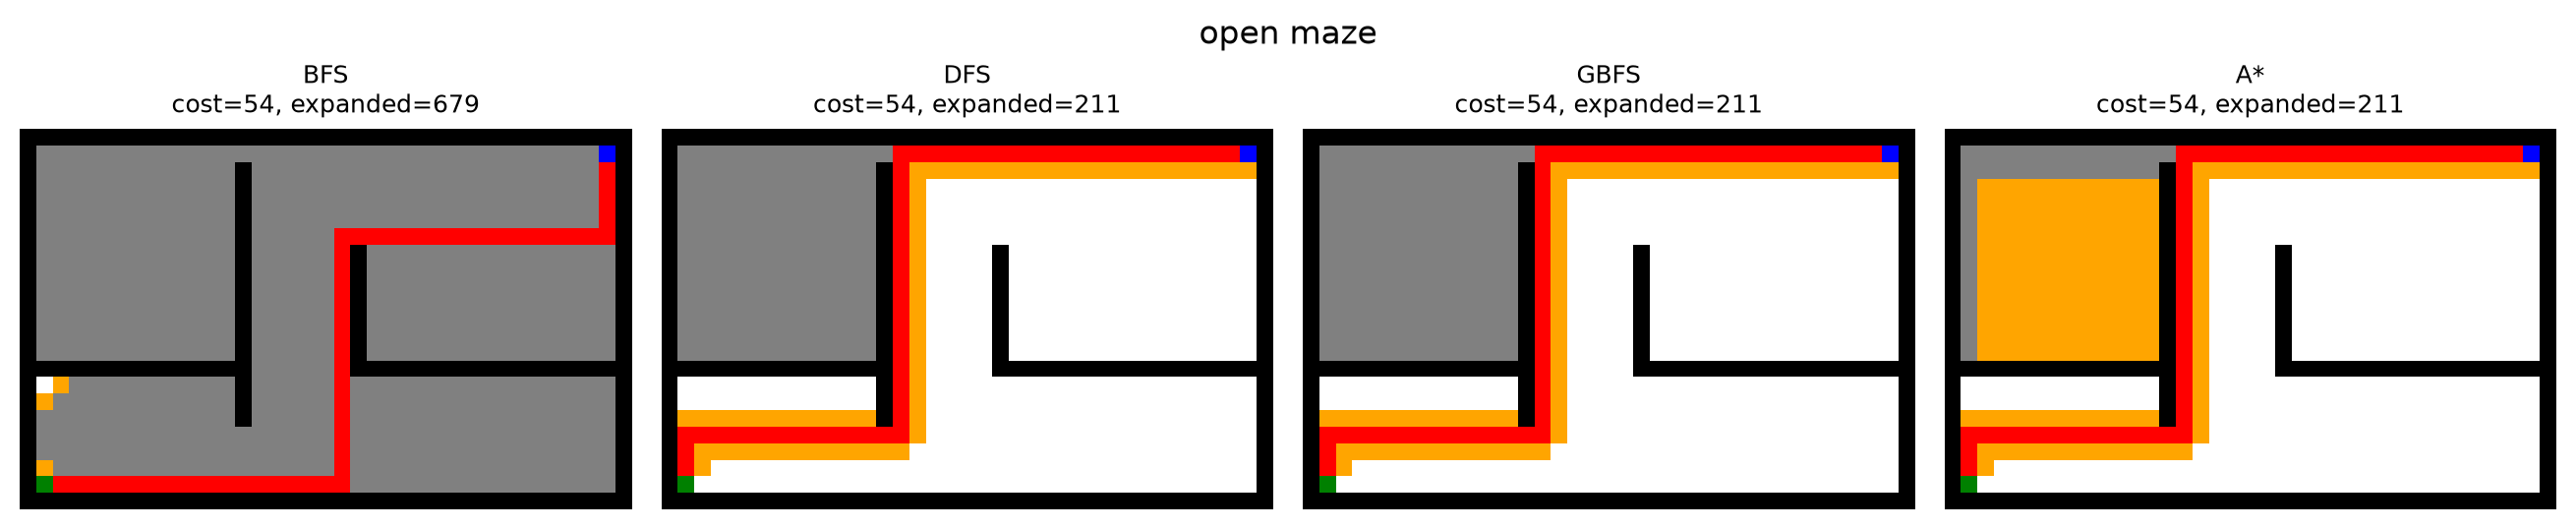

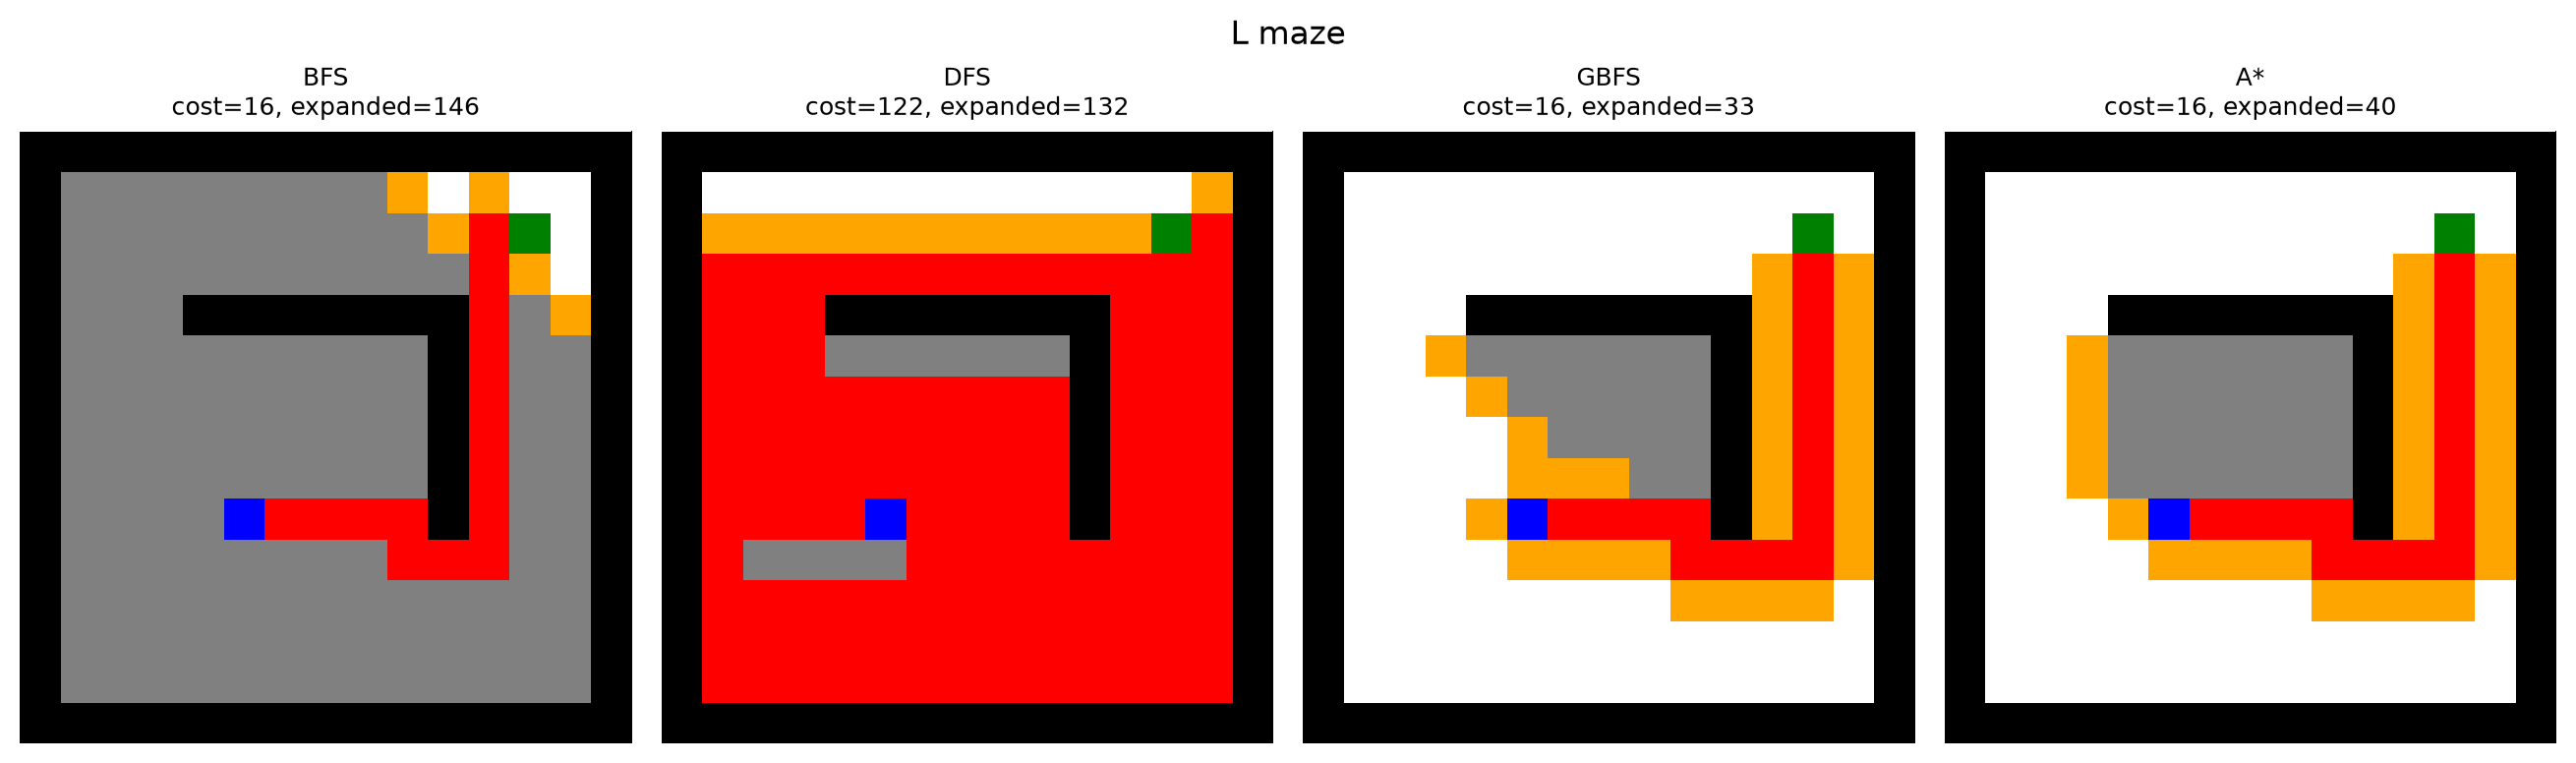

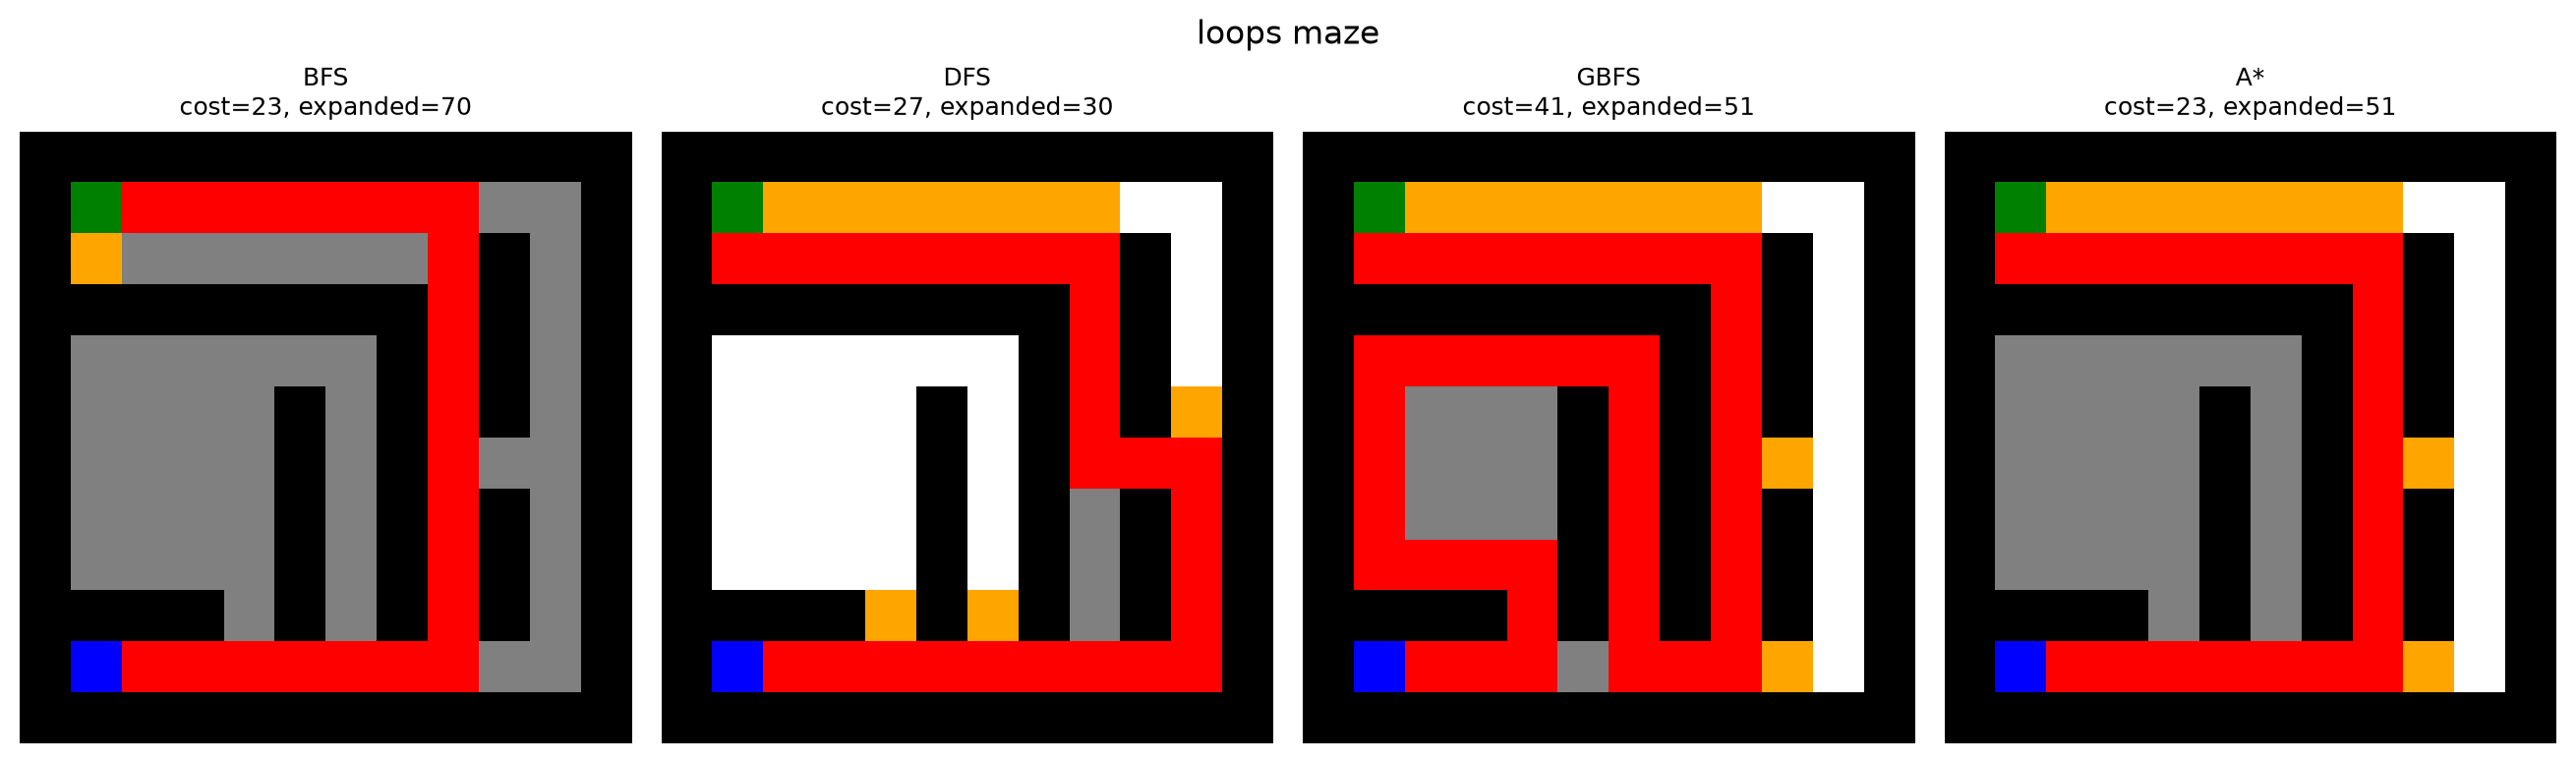

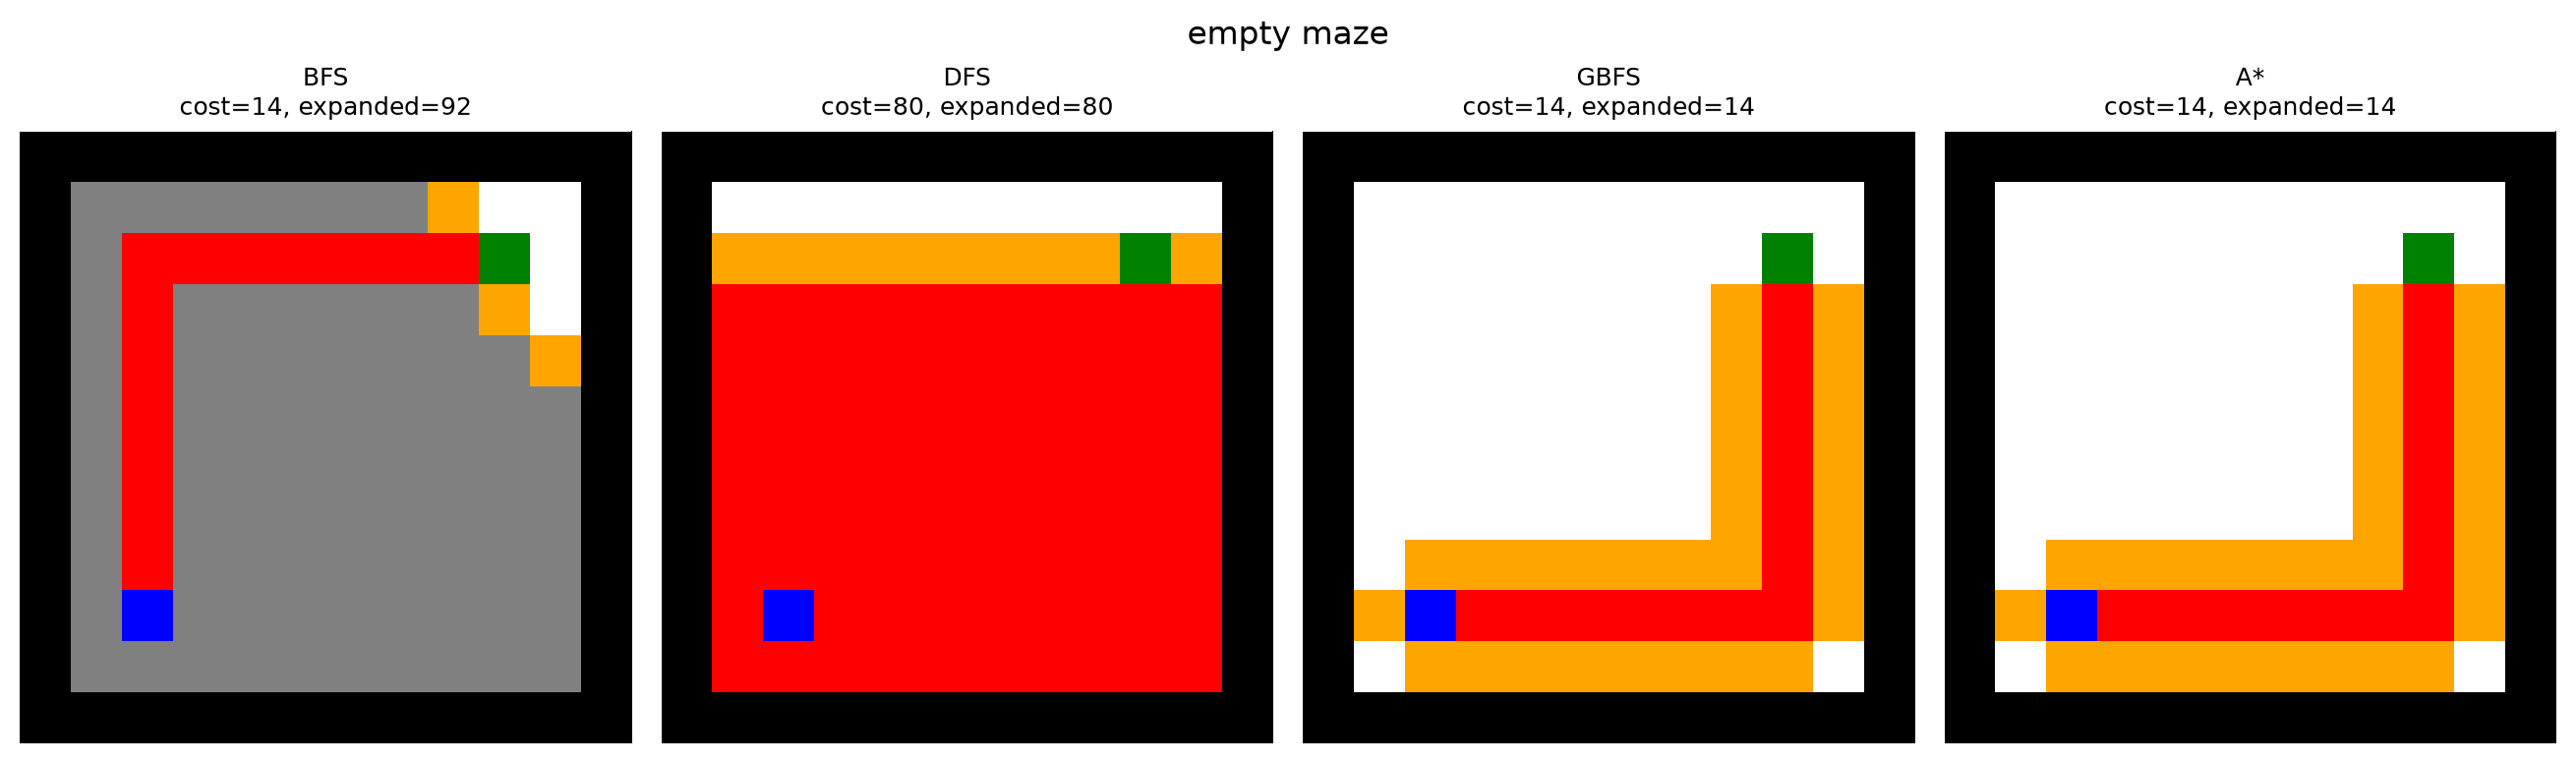

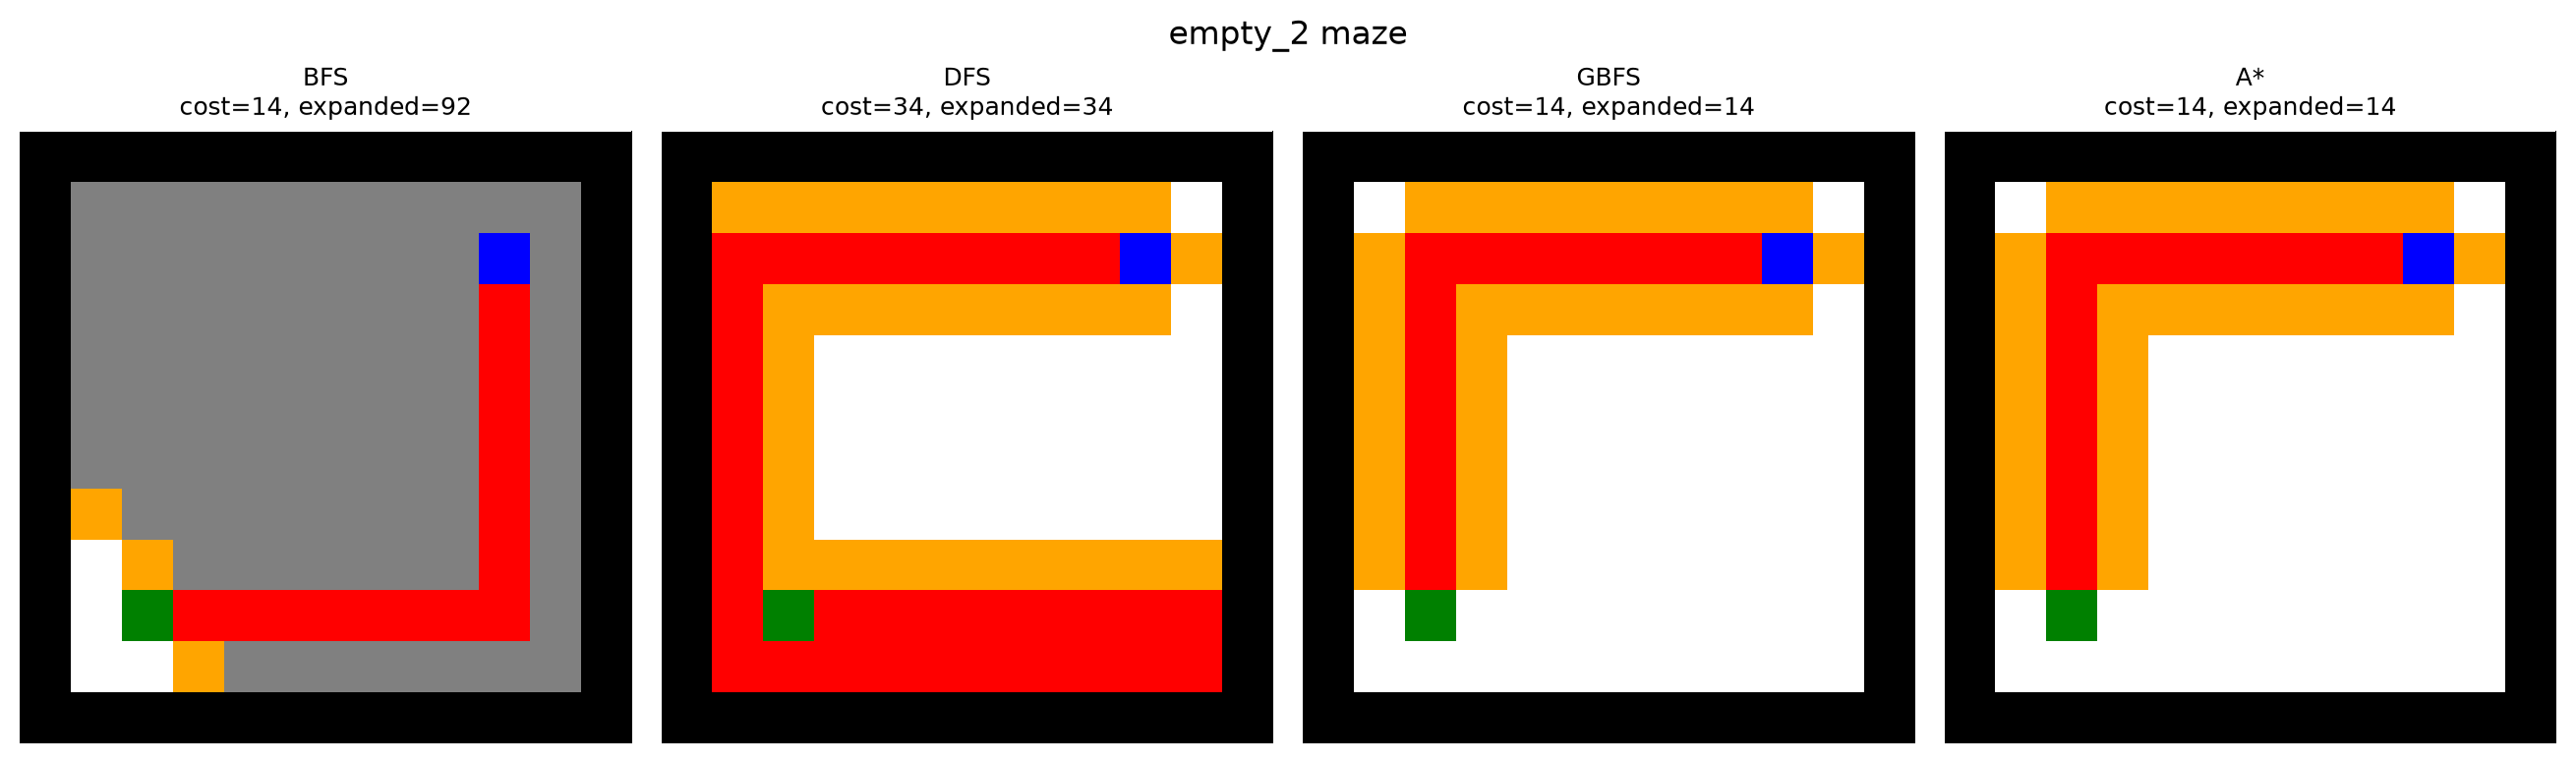

In [19]:
for name, maze in MAZES.items():
    show_solutions(maze, results[name], f"{name} maze")

Bảng kết quả cho từng mê cung (sinh tự động từ `table` ở trên để số liệu luôn khớp với lần chạy). Thời gian chạy có thể thay đổi giữa các lần chạy; các cột còn lại là tất định.

In [20]:
from IPython.display import Markdown, display

cols = ["path cost", "# of nodes expanded", "max tree depth",
        "max # of nodes in memory", "max frontier size", "time (ms)"]
for name in MAZES:
    sub = table[table["maze"] == name].set_index("algorithm")[cols].astype(object)
    lines = ["| algorithm | " + " | ".join(cols) + " |", "|---" * (len(cols) + 1) + "|"]
    lines += [f"| {alg} | " + " | ".join(str(v) for v in row) + " |" for alg, row in sub.iterrows()]
    display(Markdown(f"__{name} maze__\n\n" + "\n".join(lines)))

__small maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 19 | 90 | 19 | 93 | 9 | 0.26 |
| DFS | 29 | 39 | 29 | 34 | 5 | 0.14 |
| GBFS | 29 | 39 | 29 | 44 | 5 | 0.14 |
| A* | 19 | 51 | 19 | 58 | 7 | 0.18 |

__medium maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 68 | 267 | 68 | 270 | 9 | 0.68 |
| DFS | 152 | 153 | 152 | 160 | 8 | 0.82 |
| GBFS | 152 | 155 | 152 | 163 | 8 | 0.53 |
| A* | 68 | 217 | 68 | 224 | 8 | 0.67 |

__large maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 210 | 618 | 210 | 622 | 8 | 1.47 |
| DFS | 210 | 337 | 214 | 251 | 38 | 2.08 |
| GBFS | 210 | 456 | 210 | 481 | 25 | 1.51 |
| A* | 210 | 542 | 210 | 553 | 12 | 1.65 |

__open maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 54 | 679 | 54 | 683 | 25 | 2.07 |
| DFS | 54 | 211 | 178 | 333 | 64 | 1.78 |
| GBFS | 54 | 211 | 67 | 275 | 64 | 0.84 |
| A* | 54 | 211 | 54 | 275 | 185 | 0.96 |

__L maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 16 | 146 | 16 | 152 | 17 | 0.5 |
| DFS | 122 | 132 | 122 | 231 | 23 | 0.91 |
| GBFS | 16 | 33 | 16 | 64 | 31 | 0.15 |
| A* | 16 | 40 | 16 | 69 | 29 | 0.19 |

__loops maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 23 | 70 | 23 | 72 | 8 | 0.19 |
| DFS | 27 | 30 | 27 | 39 | 11 | 0.11 |
| GBFS | 41 | 51 | 41 | 61 | 10 | 0.17 |
| A* | 23 | 51 | 23 | 61 | 11 | 0.19 |

__empty maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 14 | 92 | 14 | 96 | 12 | 0.29 |
| DFS | 80 | 80 | 80 | 153 | 12 | 0.45 |
| GBFS | 14 | 14 | 14 | 43 | 29 | 0.08 |
| A* | 14 | 14 | 14 | 43 | 29 | 0.08 |

__empty_2 maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size | time (ms) |
|---|---|---|---|---|---|---|
| BFS | 14 | 92 | 14 | 96 | 11 | 0.29 |
| DFS | 34 | 34 | 34 | 76 | 32 | 0.19 |
| GBFS | 14 | 14 | 14 | 43 | 29 | 0.08 |
| A* | 14 | 14 | 14 | 43 | 29 | 0.08 |

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

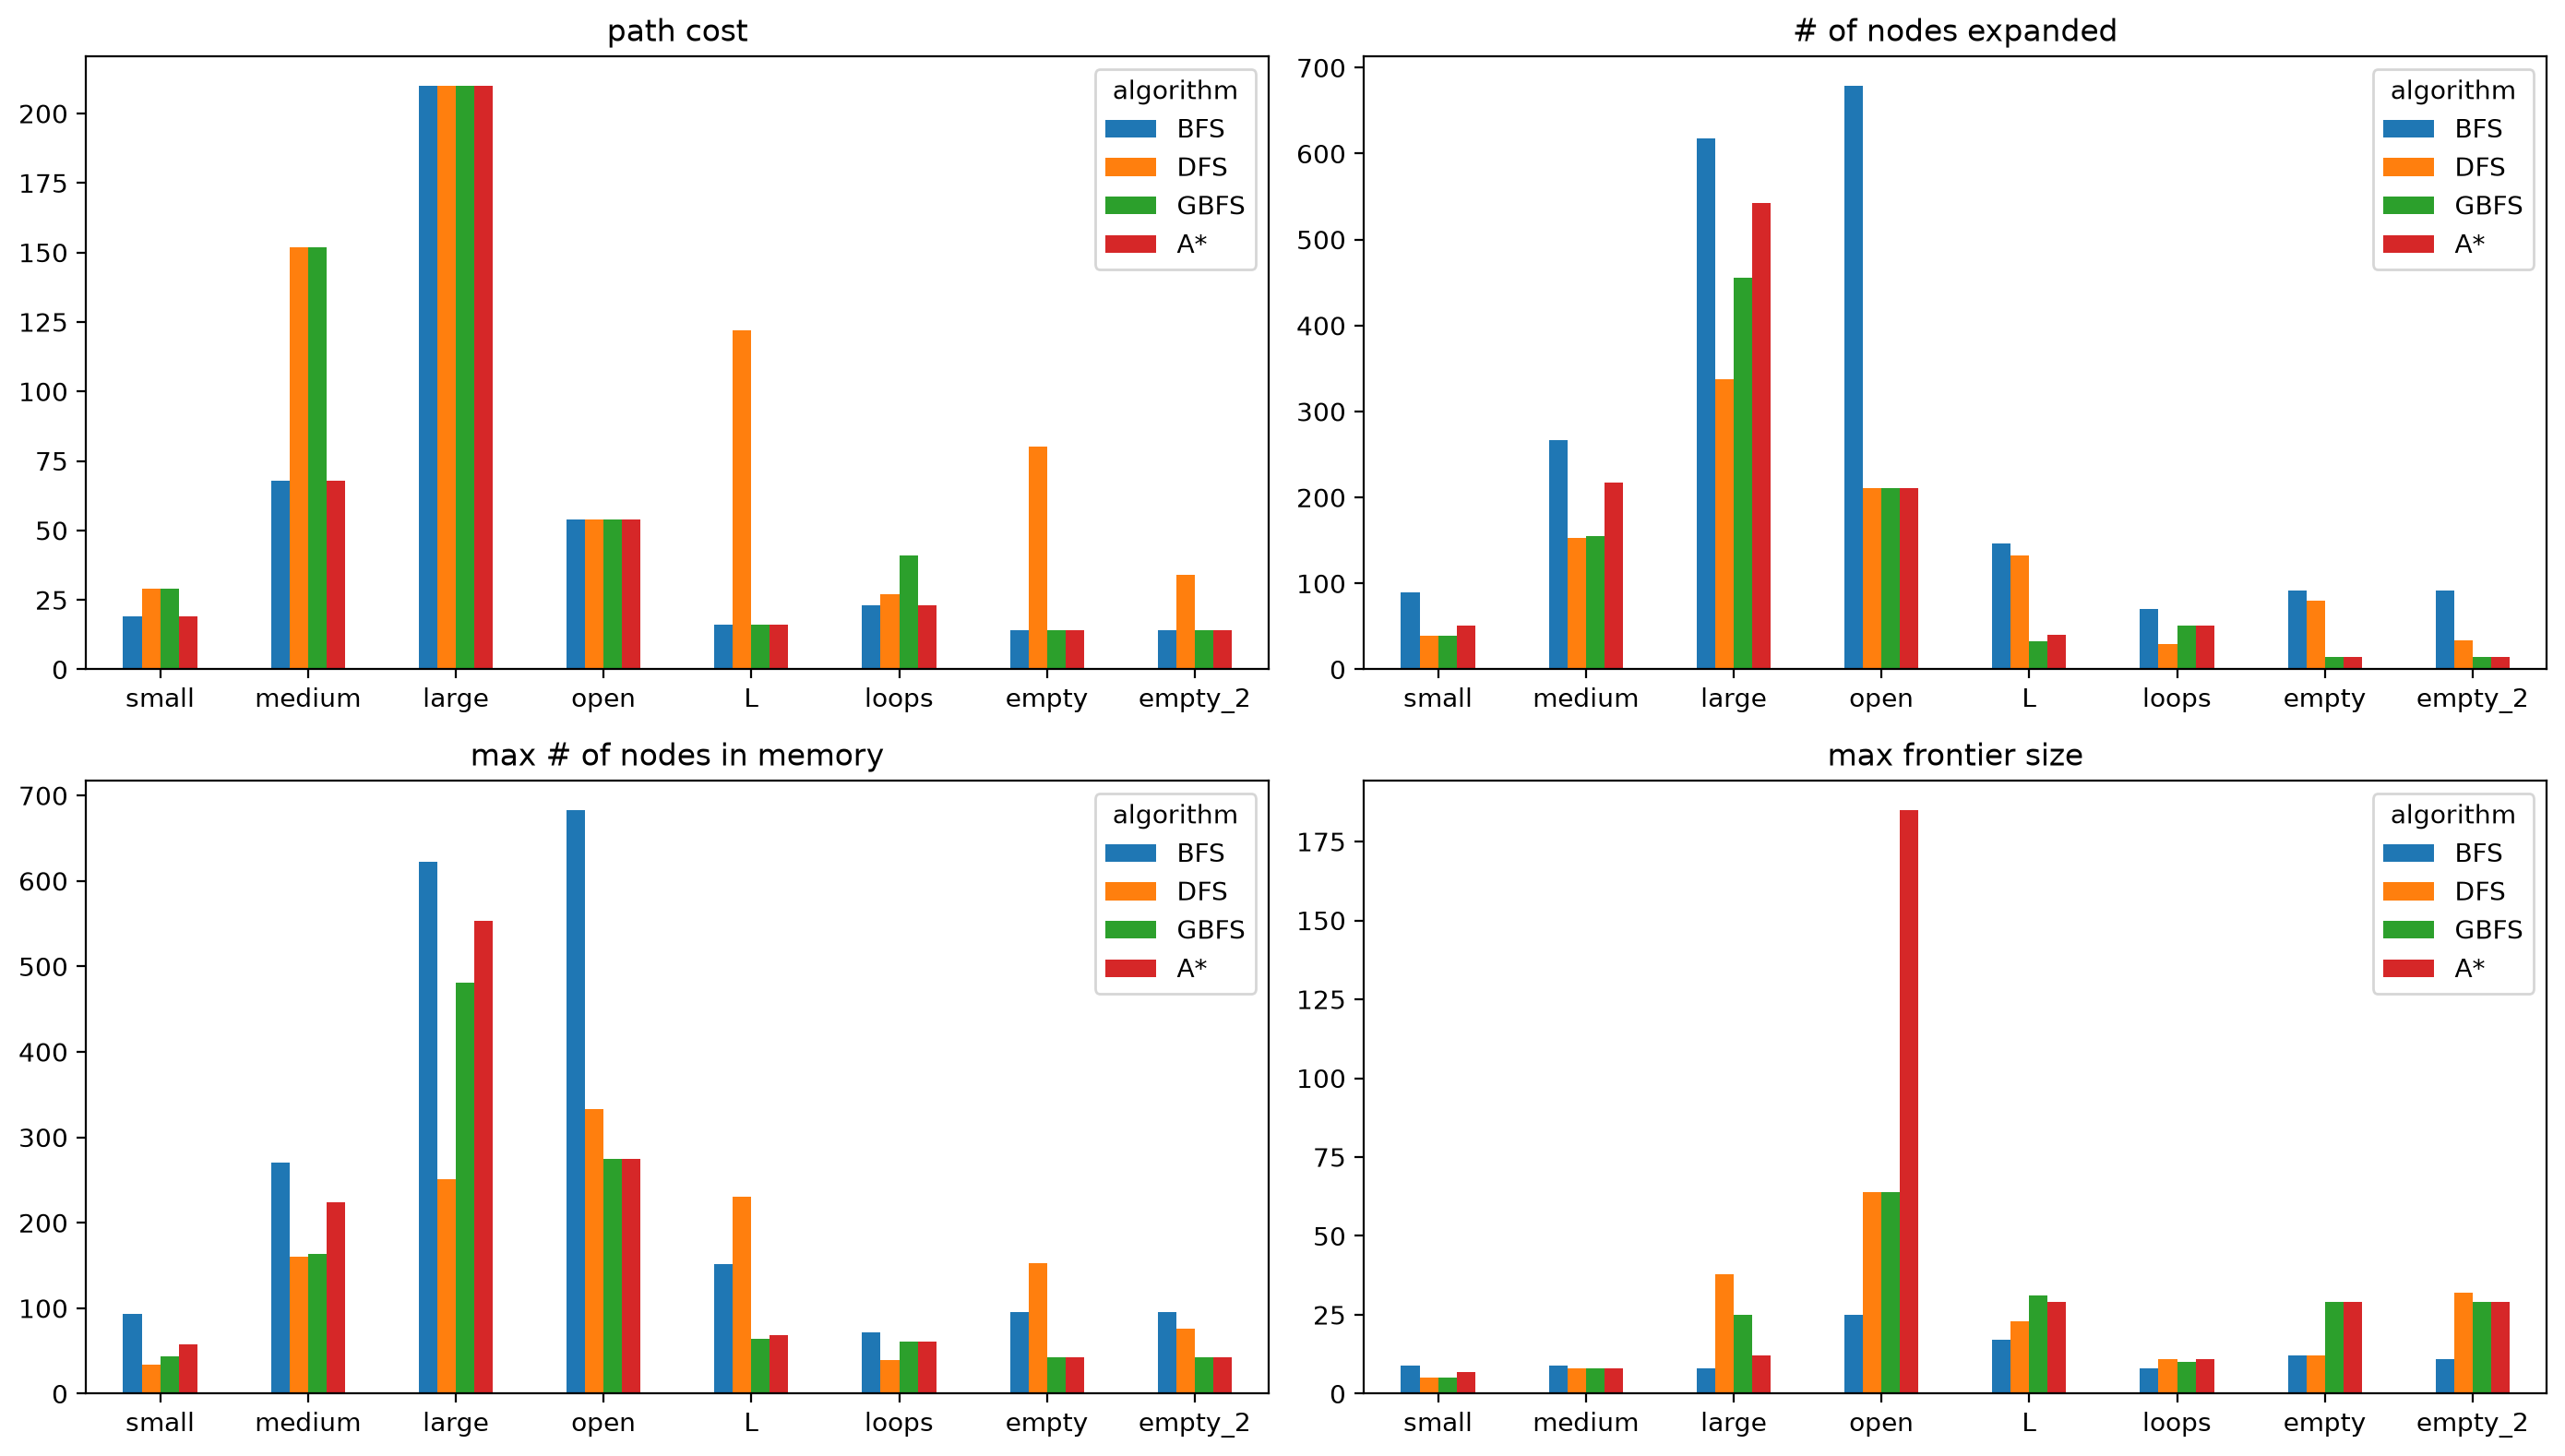

In [21]:
metrics = ["path cost", "# of nodes expanded", "max # of nodes in memory", "max frontier size"]
plot_df = table.copy()
plot_df["path cost"] = pd.to_numeric(plot_df["path cost"], errors="coerce")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, metric in zip(axes.flat, metrics):
    plot_df.pivot(index="maze", columns="algorithm", values=metric)[list(ALGORITHMS)] \
        .loc[list(MAZES)].plot.bar(ax=ax, rot=0)
    ax.set_title(metric)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Discuss the most important lessons you have learned from implementing the different search strategies. 

**Những bài học quan trọng**

1. **BFS và A\* luôn cho đường đi ngắn nhất** (chi phí bước bằng nhau, Manhattan chấp nhận được), còn **DFS và GBFS thì không**. Chênh lệch lớn nhất ở L maze (DFS 122 / tối ưu 16), empty maze (DFS 80 / 14), medium maze (DFS, GBFS 152 / 68) và loops maze (GBFS 41 / 23).
2. **Heuristic làm giảm mạnh vùng phải khảo sát.** A\* mở rộng ít nút hơn BFS ở mọi mê cung (open: 211 so với 679; L: 40 so với 146; empty: 14 so với 92). Ở mê cung "chỉ một lời giải" như large maze, mọi thuật toán phải đi gần như toàn bộ hành lang nên lợi ích của heuristic nhỏ (542 so với 618).
3. **Bộ nhớ.** BFS phải giữ toàn bộ `reached`. DFS không `reached` chỉ giữ $O(bm)$ nút: large maze 251 so với 622 của BFS. Nhưng khi đường đi DFS rất dài (empty, L maze) thì $m$ lớn và lợi thế này biến mất. A\*/GBFS cũng giữ `reached`, nên bộ nhớ chỉ nhỏ khi heuristic dẫn đường tốt.
4. **Kiểm tra chu trình trong DFS là khó trong vùng trống.** Chỉ kiểm tra đường đi hiện tại là đủ để không lặp vô hạn về lý thuyết, nhưng số đường đơn trong vùng trống tăng theo hàm mũ (open maze không giải được trong 200 000 lần lặp). Phải quản lý frontier (`move_top`) mới giải được – xem thí nghiệm Bài 7 trong 05_Maze_Example-Animation_Cycle_checking.ipynb.
5. **Hòa điểm (tie-breaking) và thứ tự sinh con quan trọng.** Trong mê cung trống có rất nhiều nút cùng $f = C^*$; ưu tiên nút mới nhất (LIFO) giúp A\* đi thẳng tới đích (14 nút) thay vì quét cả hình chữ nhật. Thứ tự hướng đi quyết định gần như toàn bộ hành vi của DFS.

**Trả lời các câu hỏi thảo luận (mục 4.3 của đề)**

* *Khi nào BFS dùng nhiều bộ nhớ hơn A\*?* Khi có vùng trống hoặc nhiều nhánh mà đích nằm theo một hướng rõ ràng: BFS loang đều mọi hướng, còn A\* chỉ mở rộng các nút có $f(n) \le C^*$. Heuristic càng sát $h^*$ thì tập $\{n : g(n)+h(n) < C^*\}$ càng nhỏ.
* *Vì sao DFS cho đường đi rất dài / gặp vấn đề với chu trình?* DFS đi sâu theo thứ tự hành động cố định và trả về lời giải **đầu tiên** gặp; không có `reached` nên phải tự chặn chu trình, và trong vùng trống có thể đi lại cùng một vùng theo nhiều đường khác nhau.
* *Vì sao thứ tự sinh con ảnh hưởng mạnh đến DFS mà ít đến BFS?* DFS luôn đi theo con đầu tiên trên stack cho tới tận cùng, nên thứ tự quyết định nhánh nào được thử trước. BFS mở rộng hết theo từng lớp độ sâu; thứ tự chỉ đổi thứ tự trong cùng một lớp và có thể đổi *đường* tối ưu cụ thể, không đổi chi phí.
* *GBFS và A\*:* GBFS chỉ dùng $h(n)$; A\* dùng $f(n) = g(n) + h(n)$. Bỏ $g(n)$ khiến GBFS mất tính tối ưu; A\* tối ưu khi $h$ chấp nhận được/nhất quán.
* *Manhattan và Euclidean trên lưới 4 hướng:* Manhattan bằng đúng số bước khi không có tường ($h = h^*$); Euclidean nhỏ hơn (đường chéo không đi được) nên kém thông tin hơn: $h_E \le h_M \le h^*$ – xem chi tiết trong 06_Explore_heuristics.ipynb.
* *Weighted A\*:* Tăng $w$ làm thuật toán tin vào heuristic hơn, giảm số nút mở rộng nhưng có thể mất tối ưu (chi phí $\le w \cdot C^*$); $w \to \infty$ thành GBFS. Xem thí nghiệm ở cuối notebook.
* *Chi phí của cycle checking:* kiểm tra đường đi tốn $O(m)$ mỗi lần sinh con; quản lý frontier (`in_frontier`, xóa lười) tốn thêm bảng băm và các bản ghi chết trong stack.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [22]:
def ids(maze, max_limit=1000, max_tries=1_000_000, frontier_option="path"):
    """Iterative deepening: gọi DFS giới hạn độ sâu với limit = 0, 1, 2, ...

    max_tries áp dụng cho từng lần lặp; nếu vượt thì dừng và báo "max_tries".
    """
    t0 = time.perf_counter()
    total_expanded = max_frontier = max_memory = 0
    for limit in range(max_limit + 1):
        res = dfs(maze, limit=limit, max_tries=max_tries, frontier_option=frontier_option)
        total_expanded += res["expanded"]
        max_frontier = max(max_frontier, res["max_frontier"])
        max_memory = max(max_memory, res["max_memory"])
        if res["status"] != "cutoff":          # tìm thấy, thất bại hẳn, hoặc vượt max_tries
            break
    res.update(expanded=total_expanded, max_frontier=max_frontier, max_memory=max_memory,
               time_ms=(time.perf_counter() - t0) * 1000, limit=limit)
    return res


ids_rows = []
for name, maze in MAZES.items():
    for option in ["path", "move_top"]:
        r = ids(maze, frontier_option=option)
        ids_rows.append({
            "maze": name, "cycle check": option,
            "path cost": r["path_cost"] if r["path"] else "N/A*",
            "optimal d": results[name]["BFS"]["path_cost"],
            "final limit": r["limit"], "status": r["status"],
            "# of nodes expanded": r["expanded"],
            "max # of nodes in memory": r["max_memory"],
            "max frontier size": r["max_frontier"],
            "time (ms)": round(r["time_ms"], 1),
        })
pd.DataFrame(ids_rows).set_index(["maze", "cycle check"])

path cost  optimal d  final limit     status  \
maze    cycle check                                                
small   path               19         19           19     solved   
        move_top           29         19           29     solved   
medium  path               68         68           68     solved   
        move_top           70         68           70     solved   
large   path              210        210          210     solved   
        move_top          210        210          210     solved   
open    path             N/A*         54           15  max_tries   
        move_top           54         54           54     solved   
L       path             N/A*         16           14  max_tries   
        move_top           42         16           43     solved   
loops   path               23         23           23     solved   
        move_top           27         23           27     solved   
empty   path               14         14           14     solved   
        move_top           20         14           21     solved   
empty_2 path               14         14           14     solved   
        move_top           16         14           16     solved   

                     # of nodes expanded  max # of nodes in memory  \
maze    cycle check                                                  
small   path                         923                        25   
        move_top                    1583                        34   
medium  path                       15665                        75   
        move_top                    9594                        77   
large   path                       60179                       248   
        move_top                   60179                       248   
open    path                      650515                        43   
        move_top                 1009028                       137   
L       path                      827299                        37   
        move_top                   16555                        97   
loops   path                       60701                        36   
        move_top                    1279                        39   
empty   path                      297368                        33   
        move_top                    1401                        48   
empty_2 path                      204382                        39   
        move_top                    1565                        42   

                     max frontier size  time (ms)  
maze    cycle check                                
small   path                         6        2.9  
        move_top                     6        4.9  
medium  path                         8       61.2  
        move_top                     8       36.3  
large   path                        38      298.8  
        move_top                    38      299.3  
open    path                        28     3477.1  
        move_top                    84     6793.4  
L       path                        23     3839.9  
        move_top                    32       90.7  
loops   path                        14      232.3  
        move_top                    11        5.0  
empty   path                        19     1497.7  
        move_top                    16        6.9  
empty_2 path                        25     1011.0  
        move_top                    25        7.3

**Nhận xét IDS**

* Với kiểm tra chu trình **chỉ trên đường đi** (`path`), mỗi lần lặp là một DLS đầy đủ, nên IDS **đầy đủ và tối ưu**: ở mọi mê cung giải được, chi phí đúng bằng $d$ của BFS, trong khi bộ nhớ chỉ $O(bd)$ (ví dụ medium: 75 nút so với 270 của BFS).
* Cái giá là **thời gian**: mỗi lần tăng giới hạn phải tìm lại từ đầu, và không có `reached` nên số đường đơn có độ dài $\le \ell$ tăng theo hàm mũ trong vùng trống. Empty maze cần khoảng 300 000 lần mở rộng (BFS: 92). Với **open maze** ($d = 54$) và **L maze**, một lần lặp duy nhất ở độ sâu 13–15 đã vượt 1 000 000 lần lấy nút → ghi **N/A\***. Đây là giới hạn của thuật toán (không `reached` ⇒ không loại được đường dư thừa), không phải lỗi cài đặt.
* Dùng `move_top` thì IDS chạy nhanh và giải được mọi mê cung, nhưng **mất tính tối ưu** (small: 29, L: 42, empty: 20 thay vì 19, 16, 14). Lý do: `move_top` xóa bản ghi nông của một trạng thái khỏi frontier và thay bằng bản ghi sâu hơn; với giới hạn độ sâu, bản ghi sâu có thể bị cắt ở `limit` nên DLS bỏ sót lời giải ở đúng độ sâu đó (L maze: tìm thấy đường dài 42 chỉ khi limit = 43). Đây chính là lưu ý trong đề: *IDS phụ thuộc vào cơ chế kiểm tra chu trình của DFS*.

### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [23]:
def add_goals(maze, goals):
    """Bản sao của mê cung với thêm các ô đích."""
    m = np.copy(maze)
    for g in goals:
        assert m[g] == " ", f"{g} is not free"
        m[g] = "G"
    return m


medium = MAZES["medium"]
MULTI = {
    "medium + 1 goal (9,33)": add_goals(medium, [(9, 33)]),
    "medium + 2 goals (5,20), (13,1)": add_goals(medium, [(5, 20), (13, 1)]),
}

MULTI_ALGS = {"BFS": bfs, "DFS": dfs, "IDS": ids, "A*": astar}
multi_results = {name: {a: alg(m) for a, alg in MULTI_ALGS.items()} for name, m in MULTI.items()}

pd.DataFrame([
    {"maze": name, "algorithm": a, "path cost": r["path_cost"],
     "goal reached": r["path"][-1], "# of nodes expanded": r["expanded"],
     "max # of nodes in memory": r["max_memory"]}
    for name, rs in multi_results.items() for a, r in rs.items()
]).set_index(["maze", "algorithm"])

path cost goal reached  \
maze                            algorithm                           
medium + 1 goal (9,33)          BFS               23      (9, 33)   
                                DFS              152      (16, 1)   
                                IDS               23      (9, 33)   
                                A*                23      (9, 33)   
medium + 2 goals (5,20), (13,1) BFS               24      (5, 20)   
                                DFS              107      (13, 1)   
                                IDS               24      (5, 20)   
                                A*                24      (5, 20)   

                                           # of nodes expanded  \
maze                            algorithm                        
medium + 1 goal (9,33)          BFS                         57   
                                DFS                        153   
                                IDS                        624   
                                A*                          30   
medium + 2 goals (5,20), (13,1) BFS                         61   
                                DFS                        108   
                                IDS                        662   
                                A*                          42   

                                           max # of nodes in memory  
maze                            algorithm                            
medium + 1 goal (9,33)          BFS                              60  
                                DFS                             160  
                                IDS                              26  
                                A*                               33  
medium + 2 goals (5,20), (13,1) BFS                              64  
                                DFS                             112  
                                IDS                              27  
                                A*                               45

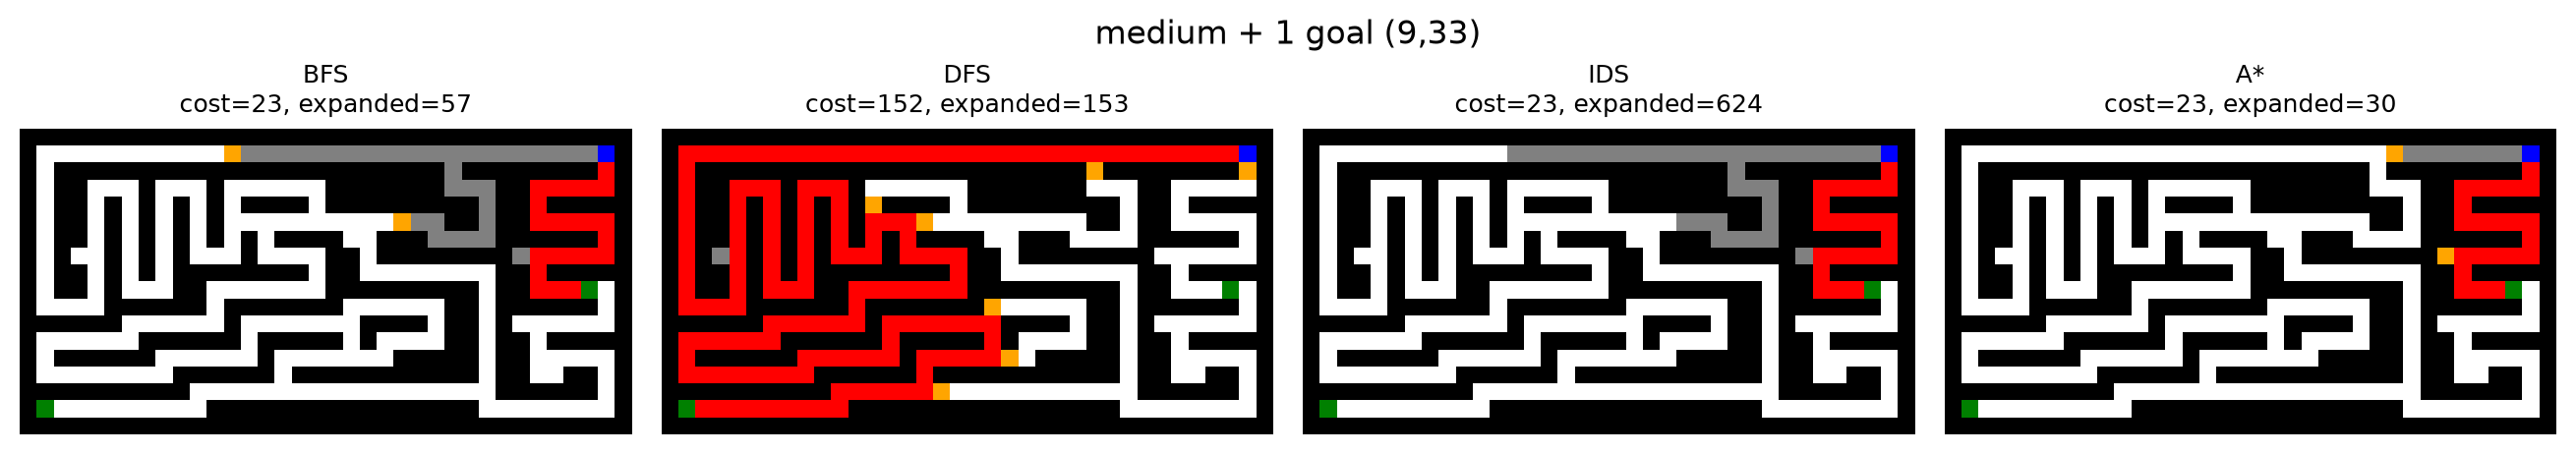

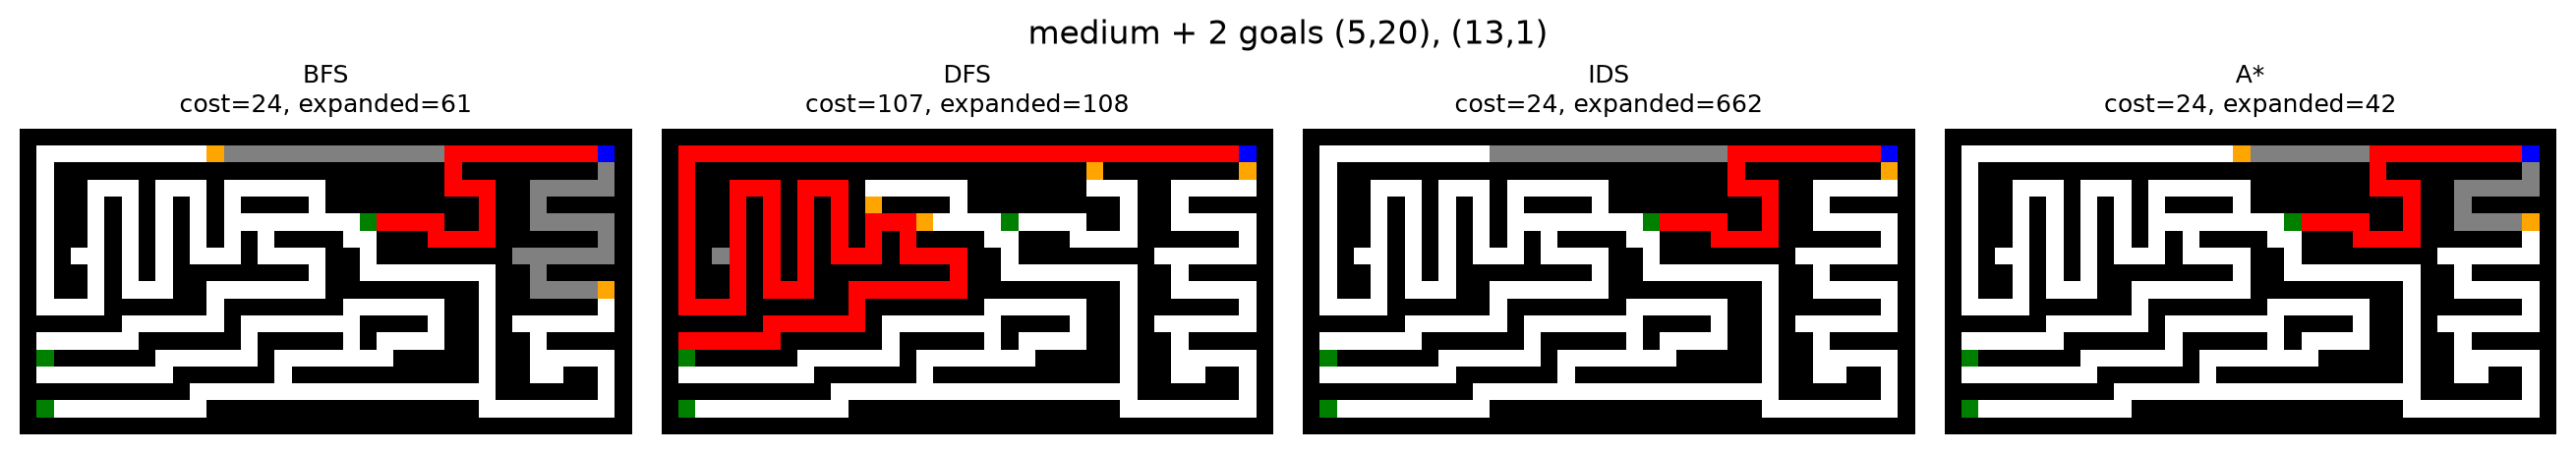

In [24]:
for name, m in MULTI.items():
    show_solutions(m, multi_results[name], name)

**Nhận xét bài toán nhiều đích.** Đích là *bất kỳ* ô `G` nào, nên lời giải tối ưu là đường tới đích **gần nhất**.

* **BFS** và **IDS** (kiểm tra chu trình theo đường đi) đều tối ưu: chúng duyệt theo độ sâu tăng dần nên đích đầu tiên gặp là đích nông nhất – không cần biết có bao nhiêu đích.
* **DFS** không tối ưu: nó dừng ở đích đầu tiên trên nhánh đang đi sâu, có thể là đích xa hơn hoặc một đường vòng tới đích gần.
* **A\*** vẫn tối ưu khi dùng $h(n) = \min_{g \in G} \text{Manhattan}(n, g)$: giá trị nhỏ nhất của các heuristic chấp nhận được vẫn chấp nhận được (và nhất quán). Nếu chỉ dùng khoảng cách tới **một** đích cố định thì $h$ có thể vượt chi phí thật tới đích khác và A\* mất tính tối ưu.

## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

*Ý tưởng (không bắt buộc):* khi chỉ dùng các giao lộ làm trạng thái thì cạnh giữa hai giao lộ có chi phí bằng độ dài hành lang, tức chi phí bước **không còn bằng nhau**. BFS/IDS theo số cạnh không còn tối ưu; cần thay bằng uniform-cost search (frontier ưu tiên theo $g(n)$) hoặc iterative lengthening (tăng dần giới hạn theo chi phí thay vì độ sâu).

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [25]:
weights = [0.5, 1, 1.5, 2, 5, 100]
rows = []
for name in ["medium", "open", "L", "loops", "empty"]:
    for w in weights:
        r = best_first_search(MAZES[name], "A*", w=w)
        rows.append({"maze": name, "w": w, "path cost": r["path_cost"],
                     "# of nodes expanded": r["expanded"], "max frontier size": r["max_frontier"]})
wa = pd.DataFrame(rows)
wa.pivot(index="w", columns="maze", values=["path cost", "# of nodes expanded"])

path cost                         # of nodes expanded              \
maze          L empty loops medium open                   L empty loops   
w                                                                         
0.5          16    14    23     68   54                 124    90    71   
1.0          16    14    23     68   54                  40    14    51   
1.5          16    14    23     68   54                  37    14    52   
2.0          16    14    23     68   54                  40    14    58   
5.0          16    14    23    102   54                  42    14    68   
100.0        16    14    23    152   54                  44    14    73   

                   
maze  medium open  
w                  
0.5      241  603  
1.0      217  211  
1.5      229  329  
2.0      227  435  
5.0      226  633  
100.0    157  717

$f(n) = g(n) + w\,h(n)$.

* $w < 1$: gần uniform-cost search (BFS) – vẫn tối ưu nhưng mở rộng nhiều nút hơn (open: 603, empty: 90 nút so với 211 và 14 của A\*).
* $w = 1$: A\* chuẩn, tối ưu.
* $w > 1$: heuristic bị "thổi phồng" nên không còn chấp nhận được/nhất quán; chỉ bảo đảm chi phí $\le w \cdot C^*$. Medium maze cho thấy chất lượng giảm rõ: 68 → 102 ($w=5$) → 152 ($w=100$, giống GBFS). Số nút mở rộng **không** luôn giảm: ở open maze heuristic kéo tác tử vào căn phòng phía trên (ngõ cụt) và vì $h$ không còn nhất quán nên A\* phải mở lại các trạng thái khi tìm thấy đường rẻ hơn (435 nút với $w=2$, 717 với $w=100$). Lợi ích tốc độ của Weighted A\* chỉ rõ khi heuristic phản ánh đúng hướng tới đích (L maze: 40 → 37 nút với $w = 1.5$, chi phí vẫn 16).

### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

*Thảo luận (không bắt buộc).* Khi tác tử **không biết bản đồ**, môi trường trở thành *partially observable* và *unknown*: tác tử không biết mô hình chuyển trạng thái nên không thể lập kế hoạch trước (offline) mà phải **xen kẽ lập kế hoạch và hành động** (online search).

* **PEAS:** *Performance* – số bước tới `G` (có thể kèm số lần va tường); *Environment* – mê cung chưa biết, tĩnh, tất định, rời rạc; *Actuators* – di chuyển N/E/S/W; *Sensors* – vị trí hiện tại, tường ở 4 ô kề, có ở `G` hay không.
* **Tác tử hợp lý:** tác tử dựa trên mô hình, ghi nhớ bản đồ đã khám phá và chạy online DFS (khám phá, quay lui bằng hành động ngược lại), hoặc LRTA\* (cập nhật $h$ của ô đã đi qua). Cách đơn giản khác: lập kế hoạch trên bản đồ "lạc quan" (ô chưa biết coi như trống) và lập lại kế hoạch khi phát hiện tường.
* **Có GPS (biết khoảng cách tới đích):** dùng khoảng cách đó làm heuristic cho LRTA\* / A\* lạc quan để ưu tiên khám phá về phía đích, giảm đáng kể quãng đường khám phá.